Three-phase pure water mixture prototyping notebook

In [1125]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize

In [1126]:
import iapws95_light
import IAPWS_ice

In [1127]:
# Ice I melting curve
T_n = 273.16       # Triple point temperature (K)
T_I_min = 251.165  # Ice I melting curve pressure local minimizer (K)
p_n = 611.657      # Triple point pressure (Pa)

# p(T) melting curve
from IAPWS_ice import ice_I_melting_p
# p(T) sublimation curve
from IAPWS_ice import ice_I_sublimation_p

In [1128]:
''' Compute limit vapor density along sublimation curve.
Vapor density as a function of pressure at solid-vapor equilibrium is needed
to convert (T, p) coordinates to (rho, p) coordinates for IAPWS-95 in the
liquid and vapor regions. '''

limit_curve_T_range = (np.linspace(140, T_n, 1001))[::-1]
limit_curve_rhov_range = np.zeros_like(limit_curve_T_range)
rho_min_global = 1e-12
rho_max_global = iapws95_light.prho_sat(273.16)["rho_satv"]

num_iter_max = 100
for i, T in enumerate(limit_curve_T_range):
  # Compute sublimation pressure
  p_sub = ice_I_sublimation_p(T)
  # Use previous (higher temperature) limit density as upper bound 
  if i == 0:
    rho_max = rho_max_global
  else:
    rho_max = limit_curve_rhov_range[i-1]

  # Bisect for limit density
  iter_count = 0
  a = rho_min_global
  b = rho_max
  while iter_count < num_iter_max:
    rho = 0.5 * (a + b) 
    p_iter = iapws95_light.p(rho, T)
    if p_iter > p_sub or p_iter < 0:
      b = rho
    else:
      a = rho
    iter_count += 1
    # print(p_iter)
    if np.abs(p_iter / p_sub - 1) < 1e-7:
      break 
  else:
    print(f"Max iter reached. for T = {T}. "
          + f"Used (a,b) = {rho_min_global, rho_max}")
  # Save limit density
  limit_curve_rhov_range[i] = rho

# Build linear interpolation function (upper bound on convex rho(T))
limit_curve_fn: callable = lambda T: np.interp(T, limit_curve_T_range[::-1], limit_curve_rhov_range[::-1], )

Max iter reached. for T = 273.16. Used (a,b) = (1e-12, 0.004854575724777867)


KeyboardInterrupt: 

In [ ]:
def w_pure_lv(rho, T):
  ''' Pure-phase sound speed for liquid or vapor. '''
  d = rho / iapws95_light.rhoc
  t = iapws95_light.Tc / T
  phir_d = iapws95_light.phir_d(d, t)
  phir_dd = iapws95_light.phir_dd(d, t)
  phir_dt = iapws95_light.phir_dt(d, t)
  phir_tt = iapws95_light.phir_tt(d, t)
  phi0_tt = iapws95_light.phi0_tt(d, t)

  _g1 = 1 + d * phir_d - d * t * phir_dt
  reduced = 1 + 2 * d * phir_d + d * d * phir_dd - (
    _g1 * _g1 / (t * t * (phi0_tt + phir_tt))
  )
  return np.sqrt(reduced * iapws95_light.R * T)

In [ ]:

def phase_info(T,p):
  ''' Single-phase characterization. Returns (phase, density, sound speed).
    Validity: T <  647 K, p < 200 MPa'''

  sat_triple = iapws95_light.prho_sat(T)
  # Density bound estimates
  rho_max = 1200
  rho_min = 1e-10

  # For given temperature, check phase
  if T > T_n:
    # Solid impossible below 209.9 MPa
    sat_triple = iapws95_light.prho_sat(T)
    p_sat = sat_triple["psat"]
    rho_satl = sat_triple["rho_satl"]
    rho_satv = sat_triple["rho_satv"]
    
    if p > p_sat:
      phase = "L"
      rho_min = rho_satl
    elif p < p_sat:
      phase = "V"
      rho_max = rho_satv
    else:
      phase = "LV"
      rho_max = rho_satl
      rho_min = rho_satl
  else:
    # Solid possible, L-V equilibrium impossible
    p_sub = ice_I_sublimation_p(T)
    p_melt = ice_I_melting_p(T)
    if p > p_melt:
      phase = "L"
      rho_min = 900
    elif p < p_sub:
      phase = "V"
      rho_max = limit_curve_fn(T)
    elif p == p_melt:
      phase = "LS"
      rho_min = 900
      rho_max = 1100
    elif p == p_sub:
      phase = "SV"
      rho_max = limit_curve_fn(T)
    else:
      phase = "S"

  try:
    if phase == "S":
      # Solid-phase EOS
      rho = IAPWS_ice.rho_iceI(p, T)
      w = IAPWS_ice.w_iceI(p, T)
    elif phase == "L" or phase == "LV" or phase == "LS":
      # Liquid-vapor EOS, including near-boundary values
      rho = scipy.optimize.brenth(lambda rho: iapws95_light.p(rho ,T) - p, rho_min, rho_max)
      w = w_pure_lv(rho, T)
    elif phase == "V" or phase == "SV":
      # Liquid-vapor EOS, including near-boundary values
      rho = scipy.optimize.brenth(lambda rho: iapws95_light.p(rho ,T) - p, rho_min, rho_max)
      w = w_pure_lv(rho, T)
    else:
      raise Exception(f"Unhandled phase string {phase}")
  except ValueError as e:
    debug_string = (f"Phase {phase} handling failed for (p, T) = ({p}, {T}).\n"
                    + f"rho_min = {rho_min}\n"
                    + f"rho_max = {rho_max}\n"
                    + f"p(rho_min) = {iapws95_light.p(rho_min, T)}\n"
                    + f"p(rho_max) = {iapws95_light.p(rho_max, T)}")
    raise ValueError(debug_string)from e

  return rho, w

In [ ]:
p_range = np.geomspace(1, 100e6, 400)
T_range = np.linspace(-100, 100, 401) + 273.15
mg_T, mg_p = np.meshgrid(T_range, p_range)
mg_rho = np.zeros_like(mg_T)
mg_w = np.zeros_like(mg_T)
for i, (T, p) in enumerate(zip(mg_T.ravel(), mg_p.ravel())):
  rho, w = phase_info(T, p)
  mg_rho.ravel()[i] = rho
  mg_w.ravel()[i] = w

c:\Volcano\quail_volcano\src\physics\multiphaseWLMA\iapws95_light\iapws95_light.py:372: RuntimeWarning: invalid value encountered in log
  return (np.log(d) + n_ideal[0] + n_ideal[1] * t + n_ideal[2] * np.log(t)
c:\Volcano\quail_volcano\src\physics\multiphaseWLMA\iapws95_light\iapws95_light.py:475: RuntimeWarning: overflow encountered in exp
  coeffs, np.exp(exponents)), axis=-1)
c:\Volcano\quail_volcano\src\physics\multiphaseWLMA\iapws95_light\iapws95_light.py:538: RuntimeWarning: overflow encountered in exp
  coeffs, np.exp(exponents)), axis=-1)
c:\Volcano\quail_volcano\src\physics\multiphaseWLMA\iapws95_light\iapws95_light.py:437: RuntimeWarning: overflow encountered in exp
  coeffs, np.exp(exponents)), axis=-1)
c:\Volcano\quail_volcano\src\physics\multiphaseWLMA\iapws95_light\iapws95_light.py:488: RuntimeWarning: overflow encountered in multiply
  coeffs[...,0:51] *= (d_res[0:51] - cdc) * (d_res[0:51] - 1.0 - cdc) \


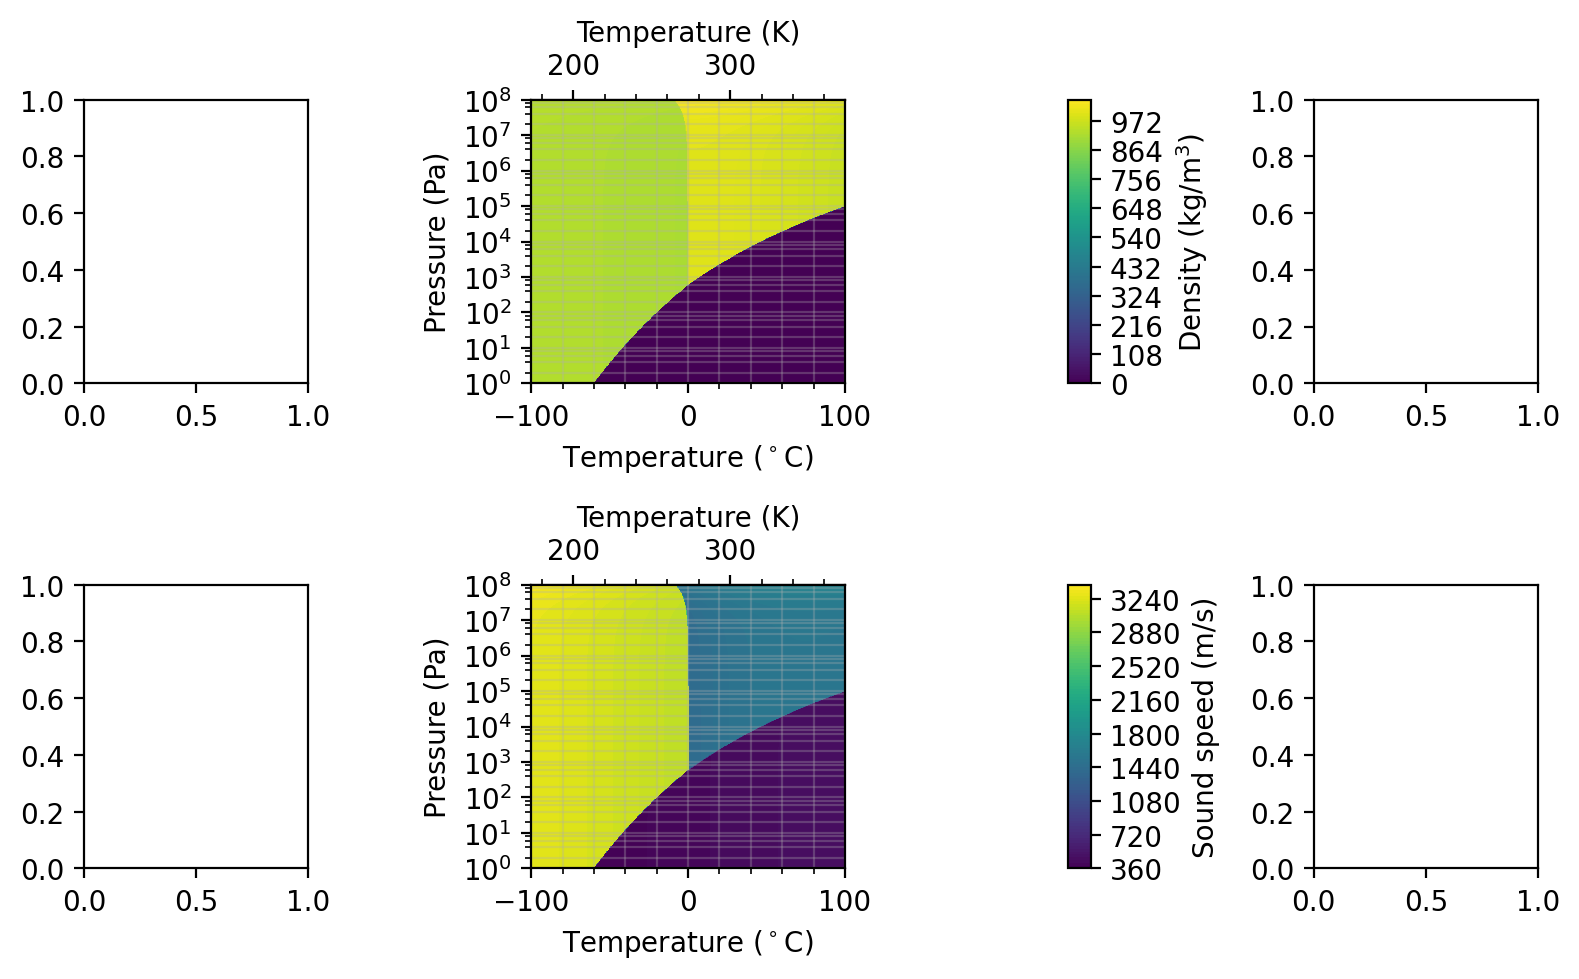

In [ ]:
from matplotlib.gridspec import GridSpec
from matplotlib import ticker

fig = plt.figure(figsize=(8,5), dpi=200)
gs = GridSpec(2, 4, width_ratios=[5, 7, .5, 5], height_ratios=[1, 1])
axes = [fig.add_subplot(gs[i]) for i in range(8)]

# Make contour plot for density
ct_rho = axes[1].contourf(mg_T - 273.15, (mg_p), mg_rho, levels=200)
axes[1].set_yscale("log")
axes[1].minorticks_on()
axes[1].grid(True, which='both', alpha=0.3)
axes[1].set_xlabel(r"Temperature (${}^\circ$C)")
axes[1].set_ylabel(r"Pressure (Pa)")
# Set Kelvin axis
secax = axes[1].secondary_xaxis('top', functions=(lambda C: C+273.15, lambda K: K-273.15))
secax.minorticks_on()
secax.set_xlabel("Temperature (K)")
# Extend log ticks
locator = ticker.LogLocator(base=10.0,subs=(1.0,),numticks=12)
axes[1].yaxis.set_major_locator(locator) 
locator = ticker.LogLocator(base=10.0,subs=(0.2,0.4,0.6,0.8, 1.0),numticks=12)
axes[1].yaxis.set_minor_locator(locator) 
axes[1].yaxis.set_minor_formatter(ticker.NullFormatter())
plt.colorbar(ct_rho, cax=axes[2], label=r"Density (kg/m${}^3$)")

# Make contour plot for sound speed
ct_w = axes[5].contourf(mg_T - 273.15, (mg_p), mg_w, levels=100)
axes[5].set_yscale("log")
axes[5].minorticks_on()
axes[5].grid(True, which='both', alpha=0.3)
axes[5].set_xlabel(r"Temperature (${}^\circ$C)")
axes[5].set_ylabel(r"Pressure (Pa)")
# Set Kelvin axis
secax = axes[5].secondary_xaxis('top', functions=(lambda C: C+273.15, lambda K: K-273.15))
secax.minorticks_on()
secax.set_xlabel("Temperature (K)")
# Extend log ticks
locator = ticker.LogLocator(base=10.0,subs=(1.0,),numticks=12)
axes[5].yaxis.set_major_locator(locator) 
locator = ticker.LogLocator(base=10.0,subs=(0.2,0.4,0.6,0.8, 1.0),numticks=12)
axes[5].yaxis.set_minor_locator(locator) 
axes[5].yaxis.set_minor_formatter(ticker.NullFormatter())
plt.colorbar(ct_w, cax=axes[6], label=r"Sound speed (m/s)", ticks=np.linspace(360, 3600, 10))

fig.tight_layout()

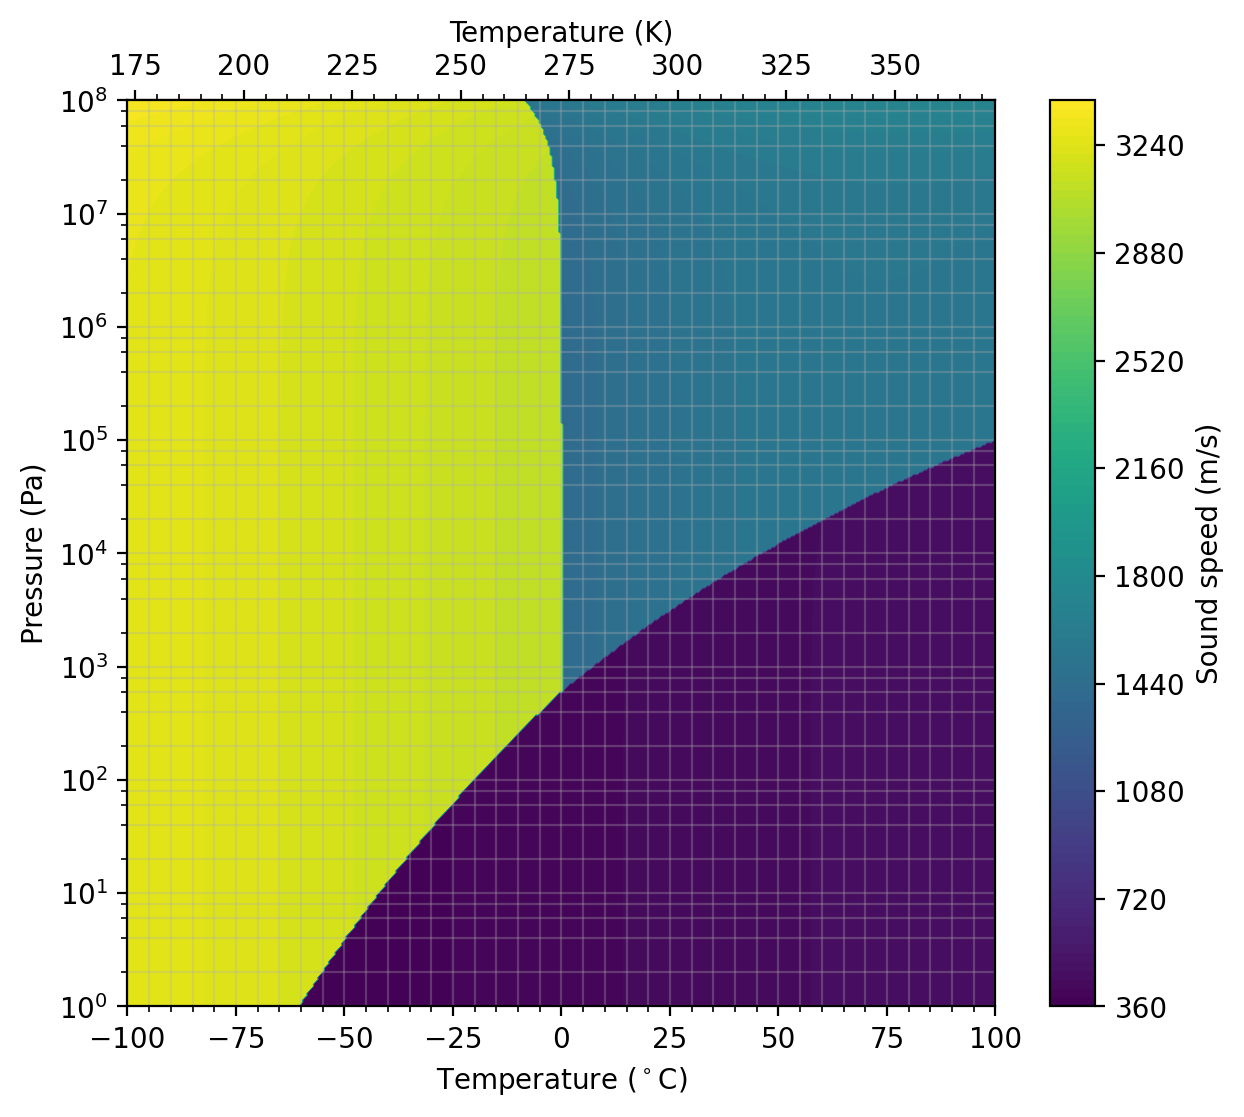

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(7,6), dpi=200)

# Make contour plot for sound speed
ct_w = ax.contourf(mg_T - 273.15, (mg_p), mg_w, levels=100)
ax.set_yscale("log")
ax.minorticks_on()
ax.grid(True, which='both', alpha=0.3)
ax.set_xlabel(r"Temperature (${}^\circ$C)")
ax.set_ylabel(r"Pressure (Pa)")
# Set Kelvin axis
secax = ax.secondary_xaxis('top', functions=(lambda C: C+273.15, lambda K: K-273.15))
secax.minorticks_on()
secax.set_xlabel("Temperature (K)")
# Extend log ticks
locator = ticker.LogLocator(base=10.0,subs=(1.0,),numticks=12)
ax.yaxis.set_major_locator(locator) 
locator = ticker.LogLocator(base=10.0,subs=(0.2,0.4,0.6,0.8, 1.0),numticks=12)
ax.yaxis.set_minor_locator(locator) 
ax.yaxis.set_minor_formatter(ticker.NullFormatter())
plt.colorbar(ct_w,label=r"Sound speed (m/s)", ticks=np.linspace(360, 3600, 10))


In [ ]:
import scipy.interpolate

# Select pressures for plotting
p_target_range = np.array([1e3, 10e3, 100e3, 1e6])

# Use cubic interpolation to find T_sat(p) that results in select pressures
T_range_interp = np.linspace(T_n, 200+273.15, 1000)
p_out = np.array([
  float(iapws95_light.prho_sat(T)["psat"]) for T in T_range_interp])
# Assemble range, including triple point pressure
T_range_LV = np.array([T_n,
  *scipy.interpolate.pchip(p_out, T_range_interp)(p_target_range) ])
# Show pressures calculated from select temperatures
[float(iapws95_light.prho_sat(T)["psat"]) for T in T_range_LV]

[611.6547822284314,
 1000.0000137216141,
 10000.000044284066,
 100000.0000037872,
 999999.9999906825]

In [ ]:
# L-V mixes

sat_triples = [iapws95_light.prho_sat(T) for T in T_range_LV]
p_range_LV = np.array([tup["psat"] for tup in sat_triples])
rho_satl_LV = np.array([tup["rho_satl"] for tup in sat_triples])
rho_satv_LV = np.array([tup["rho_satv"] for tup in sat_triples])
compressibility_L = np.empty_like(p_range_LV)
compressibility_V = np.empty_like(p_range_LV)
massfrac_L = np.linspace(0, 1.0, 5000)**0.1
w_mix_LV = np.zeros((len(massfrac_L), len(T_range_LV)))

# Compute corresponding rho * c^2
for i, T in enumerate(T_range_LV):
  compressibility_L[i] = 1 / (rho_satl_LV[i] * w_pure_lv(rho_satl_LV[i], T)**2)
  compressibility_V[i] = 1 / (rho_satv_LV[i] * w_pure_lv(rho_satv_LV[i], T)**2)
  
  # Compute vol frac conversion for this (p,T)
  rho_mix = 1.0 / (massfrac_L / rho_satl_LV[i] + (1.0-massfrac_L) / rho_satv_LV[i])
  volfrac_L = massfrac_L * rho_mix / rho_satl_LV[i]
  
  compressibility_mix = volfrac_L * compressibility_L[i] + (1.0 - volfrac_L) * compressibility_V[i]
  w_mix_LV[:,i] = np.sqrt(1 / (compressibility_mix * rho_mix))

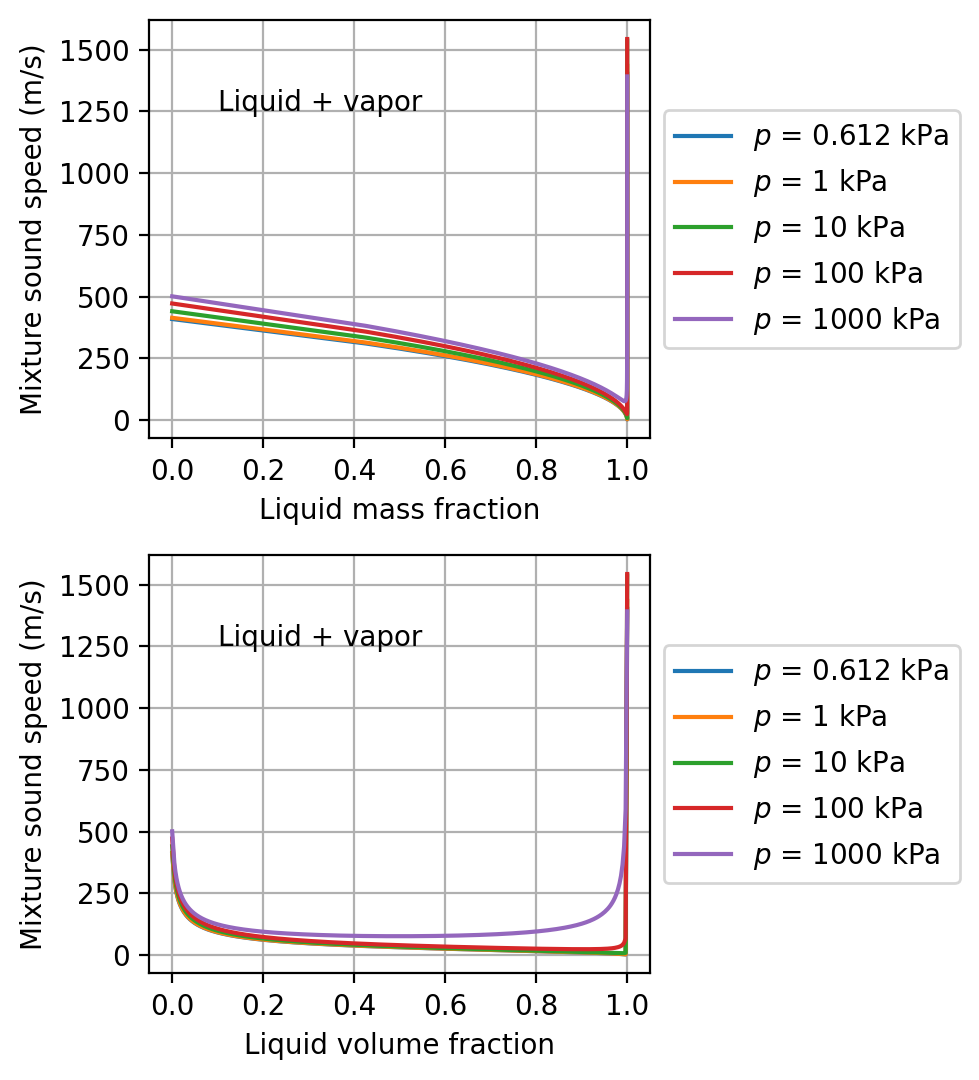

In [ ]:
fig, ax = plt.subplots(2,1,figsize=(5,5.5), dpi=200)
ax[0].plot(massfrac_L, w_mix_LV[:,0], label="$p$ = 0.612 kPa")
ax[0].plot(massfrac_L, w_mix_LV[:,1], label="$p$ = 1 kPa")
ax[0].plot(massfrac_L, w_mix_LV[:,2], label="$p$ = 10 kPa")
ax[0].plot(massfrac_L, w_mix_LV[:,3], label="$p$ = 100 kPa")
ax[0].plot(massfrac_L, w_mix_LV[:,4], label="$p$ = 1000 kPa")
ax[0].legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax[0].set_xlabel("Liquid mass fraction")
ax[0].set_ylabel("Mixture sound speed (m/s)")
ax[0].grid(True)
ax[0].text(0.1, 1250, "Liquid + vapor")
ax[1].plot(volfrac_L, w_mix_LV[:,0], label="$p$ = 0.612 kPa")
ax[1].plot(volfrac_L, w_mix_LV[:,1], label="$p$ = 1 kPa")
ax[1].plot(volfrac_L, w_mix_LV[:,2], label="$p$ = 10 kPa")
ax[1].plot(volfrac_L, w_mix_LV[:,3], label="$p$ = 100 kPa")
ax[1].plot(volfrac_L, w_mix_LV[:,4], label="$p$ = 1000 kPa")
ax[1].legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax[1].set_xlabel("Liquid volume fraction")
ax[1].set_ylabel("Mixture sound speed (m/s)")
ax[1].grid(True)
ax[1].text(0.1, 1250, "Liquid + vapor")

fig.tight_layout()

In [ ]:
# Select pressures to plot at
p_range_SV = np.array([1, 10, 100, p_n])
# Set interpolation data
T_sweep_SV = np.linspace(100, IAPWS_ice.T_n, 1000)
# Compute temperatures along sublimation curve at given pressures
T_range_SV = scipy.interpolate.pchip(IAPWS_ice.ice_I_sublimation_p(T_sweep_SV), T_sweep_SV)(p_range_SV)
# Show pressures computed from temperature points
IAPWS_ice.ice_I_sublimation_p(T_range_SV)

array([  1.        ,  10.00000011, 100.00000163, 611.657     ])

In [ ]:
# S-V mixes

# Compute density of saturated vapor at sublimation curve
rho_satv_SV = limit_curve_fn(T_range_SV)

compressibility_S = np.empty_like(p_range_SV)
compressibility_V = np.empty_like(p_range_SV)
massfrac_S = np.linspace(0, 1.0, 5000)
volfrac_S = np.linspace(0, 1.0, 5000)

# Output as a function of massfrac_S
w_mix_SV_massfrac = np.zeros((len(massfrac_S), len(T_range_SV)))
# Output as a function of volfrac_S
w_mix_SV_volfrac = np.zeros((len(volfrac_S), len(T_range_SV)))

# Compute corresponding rho * c^2
for i, T in enumerate(T_range_SV):
  p = p_range_SV[i]
  compressibility_S[i] = IAPWS_ice.compressibility_isentropic_iceI(p, T)
  compressibility_V[i] = 1 / (rho_satv_SV[i] * w_pure_lv(rho_satv_SV[i], T)**2)
  
  # Compute compressibility for this (p,T) over mass fraction range
  rho_ice = IAPWS_ice.rho_iceI(p,T)
  rho_v = rho_satv_SV[i]
  rho_mix = 1.0 / (massfrac_S / rho_ice + (1.0-massfrac_S) / rho_v)
  volfrac_S_dependent = massfrac_S * rho_mix / rho_ice  
  compressibility_mix = (volfrac_S_dependent * compressibility_S[i]
                         + (1.0 - volfrac_S_dependent) * compressibility_V[i])
  w_mix_SV_massfrac[:,i] = np.sqrt(1 / (compressibility_mix * rho_mix))

  # Compute compressibility for this (p,T) over volume fraction range
  rho_mix = volfrac_S * rho_ice + (1.0 - volfrac_S) * rho_v
  # massfrac_S_dependent = volfrac_S * rho_ice / rho_mix
  compressibility_mix = volfrac_S * compressibility_S[i] + (1.0 - volfrac_S) * compressibility_V[i]
  w_mix_SV_volfrac[:,i] = np.sqrt(1 / (compressibility_mix * rho_mix))


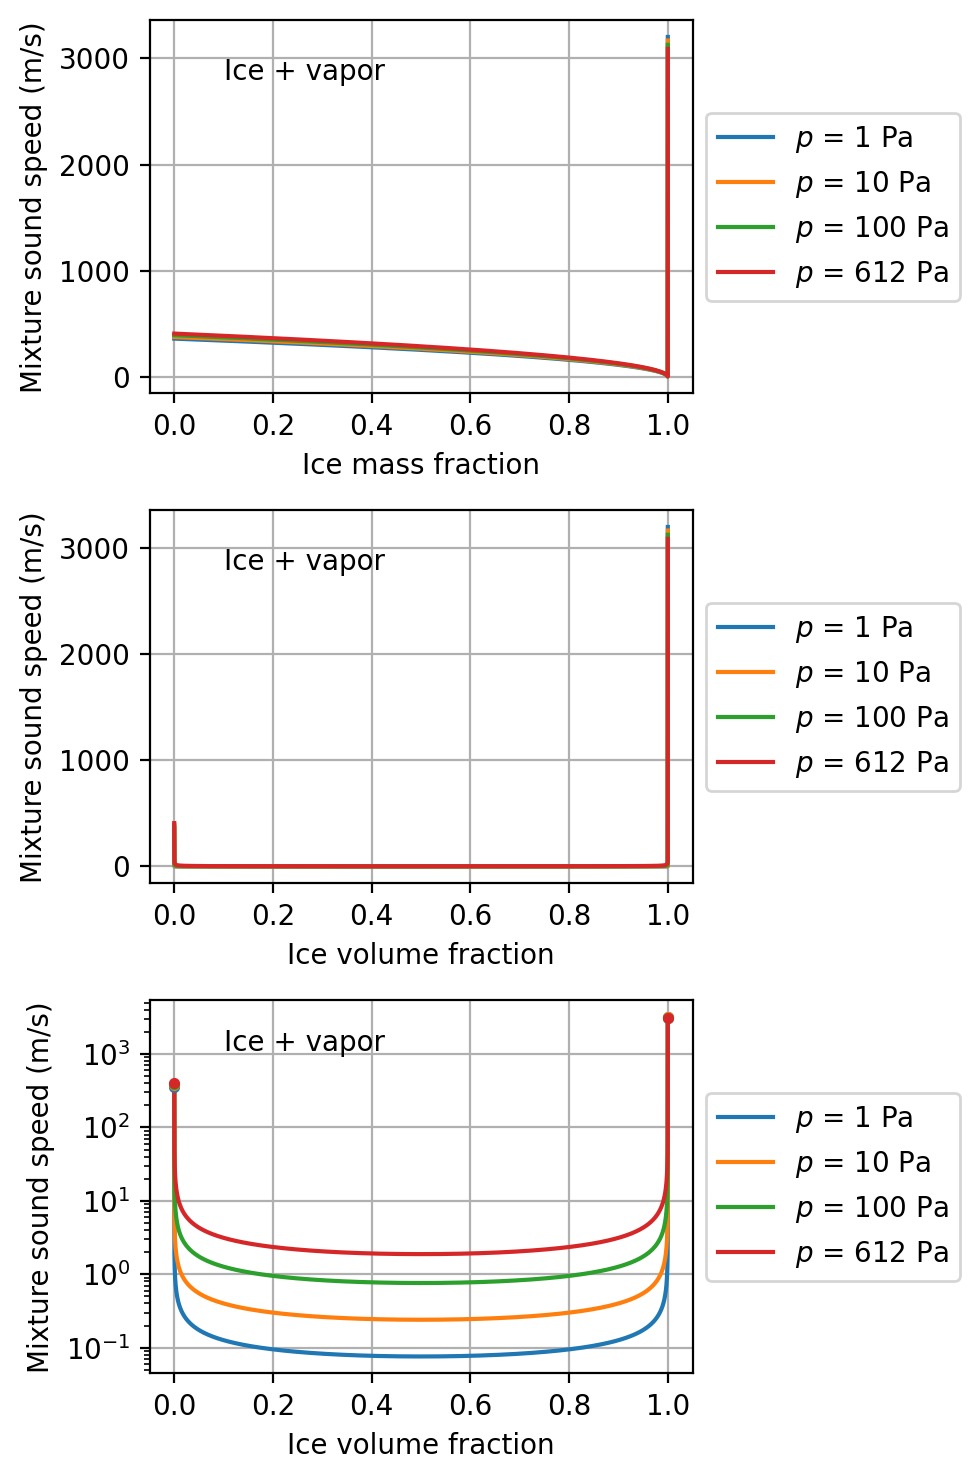

In [ ]:
fig, ax = plt.subplots(3,1,figsize=(5,7.5), dpi=200)
ax[0].plot(massfrac_S, w_mix_SV_massfrac[:,0], label="$p$ = 1 Pa")
ax[0].plot(massfrac_S, w_mix_SV_massfrac[:,1], label="$p$ = 10 Pa")
ax[0].plot(massfrac_S, w_mix_SV_massfrac[:,2], label="$p$ = 100 Pa")
ax[0].plot(massfrac_S, w_mix_SV_massfrac[:,3], label="$p$ = 612 Pa")
ax[0].legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax[0].set_xlabel("Ice mass fraction")
ax[0].set_ylabel("Mixture sound speed (m/s)")
ax[0].grid(True)
ax[0].text(0.1, 2800, "Ice + vapor")
ax[1].plot(volfrac_S, w_mix_SV_volfrac[:,0], label="$p$ = 1 Pa")
ax[1].plot(volfrac_S, w_mix_SV_volfrac[:,1], label="$p$ = 10 Pa")
ax[1].plot(volfrac_S, w_mix_SV_volfrac[:,2], label="$p$ = 100 Pa")
ax[1].plot(volfrac_S, w_mix_SV_volfrac[:,3], label="$p$ = 612 Pa")
ax[1].legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax[1].set_xlabel("Ice volume fraction")
ax[1].set_ylabel("Mixture sound speed (m/s)")
ax[1].grid(True)
ax[1].text(0.1, 2800, "Ice + vapor")
line0, = ax[2].semilogy(volfrac_S, w_mix_SV_volfrac[:,0], label="$p$ = 1 Pa")
line1, = ax[2].semilogy(volfrac_S, w_mix_SV_volfrac[:,1], label="$p$ = 10 Pa")
line2, = ax[2].semilogy(volfrac_S, w_mix_SV_volfrac[:,2], label="$p$ = 100 Pa")
line3, = ax[2].semilogy(volfrac_S, w_mix_SV_volfrac[:,3], label="$p$ = 612 Pa")
ax[2].legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax[2].set_xlabel("Ice volume fraction")
ax[2].set_ylabel("Mixture sound speed (m/s)")
ax[2].grid(True)
ax[2].text(0.1, 1100, "Ice + vapor")
ax[2].plot([0.0, 1.0], w_mix_SV_volfrac[[0, -1],0], '.', color=line0.get_color())
ax[2].plot([0.0, 1.0], w_mix_SV_volfrac[[0, -1],1], '.', color=line1.get_color())
ax[2].plot([0.0, 1.0], w_mix_SV_volfrac[[0, -1],2], '.', color=line2.get_color())
ax[2].plot([0.0, 1.0], w_mix_SV_volfrac[[0, -1],3], '.', color=line3.get_color())

fig.tight_layout()

In [ ]:
# Pick starting condition
rho_satl = iapws95_light.prho_sat(273.16)["rho_satl"]

iapws95_light.phi0(d, t)

def w_pure_lv(rho, T):
  ''' Pure-phase sound speed for liquid or vapor. '''
  d = rho / iapws95_light.rhoc
  t = iapws95_light.Tc / T
  phir_d = iapws95_light.phir_d(d, t)
  phir_dd = iapws95_light.phir_dd(d, t)
  phir_dt = iapws95_light.phir_dt(d, t)
  phir_tt = iapws95_light.phir_tt(d, t)
  phi0_tt = iapws95_light.phi0_tt(d, t)

  _g1 = 1 + d * phir_d - d * t * phir_dt
  reduced = 1 + 2 * d * phir_d + d * d * phir_dd - (
    _g1 * _g1 / (t * t * (phi0_tt + phir_tt))
  )
  return np.sqrt(reduced * iapws95_light.R * T)

NameError: name 'd' is not defined

In [ ]:
IAPWS_ice.s_iceI(p, T)
IAPWS_ice.h_iceI(p, T)
IAPWS_ice.u_iceI(p, T)
IAPWS_ice.compressibility_isentropic_iceI(p, T)

def all_pure_lv(rho, T, dump=False):
  ''' Pure-phase sound speed for liquid or vapor. '''
  d = rho / iapws95_light.rhoc
  t = iapws95_light.Tc / T
  phi0 = iapws95_light.phi0(d, t)
  phi0_t = iapws95_light.phi0_t(d, t)
  phi0_tt = iapws95_light.phi0_tt(d, t)
  phir = iapws95_light.phir(d, t)
  phir_d = iapws95_light.phir_d(d, t)
  phir_t = iapws95_light.phir_t(d, t)
  phir_dd = iapws95_light.phir_dd(d, t)
  phir_dt = iapws95_light.phir_dt(d, t)
  phir_tt = iapws95_light.phir_tt(d, t)

  _g1 = 1 + d * phir_d - d * t * phir_dt
  reduced = 1 + 2 * d * phir_d + d * d * phir_dd - (
    _g1 * _g1 / (t * t * (phi0_tt + phir_tt))
  )
  w = np.sqrt(reduced * iapws95_light.R * T)
  s = iapws95_light.R * (t * (phi0_t + phir_t) - phi0 - phir)
  h = iapws95_light.R * T * (1 + t * (phi0_t + phir_t) + d * phir_d)
  u = iapws95_light.R * T * t * (phi0_t + phir_t)
  if dump:
    return s, h, u, w, {
      "phi0": phi0,
      "phi0_t": phi0_t,
      "phi0_tt": phi0_tt,
      "phir": phir,
      "phir_d": phir_d,
      "phir_t": phir_t,
      "phir_dd": phir_dd,
      "phir_dt": phir_dt,
      "phir_tt": phir_tt,}
  else:
    return s, h, u, w

all_pure_lv(rho, T)

(array([-0.00411229]),
 array([-60.9140931]),
 array([-1.12240431]),
 array([1402.17558496]))

In [ ]:
iapws95_light.prho_sat(273.16)

{'psat': array([611.65478223]),
 'rho_satl': 999.792520031637,
 'rho_satv': 0.004854575724777867}

In [ ]:
IAPWS_ice.ice_I_sublimation_p(273.16)

611.657

In [ ]:
(e, s)

In [ ]:
# Temperature-based primary lookup


# Secondary lookup from entropy

T_MIN = 150
T_MAX = 500
ice_resolution = 101
lv_resolution = 101
IAPWS_ice.ice_I_sublimation_p(273.16)
IAPWS_ice.ice_I_sublimation_p(100)

# Independent coordinates
Tsat_ice = np.linspace(T_MIN, T_MAX, ice_resolution)
Tsat_lv = np.linspace(T_n, T_MAX, lv_resolution)
# Saturation curves
psat_ice = IAPWS_ice.ice_I_sublimation_p(Tsat_ice)
sat_triples = [iapws95_light.prho_sat(T) for T in Tsat_lv]
psat_lv, rho_satl, rho_satv = zip(*[(
  float(tup["psat"]), tup["rho_satl"], tup["rho_satv"])
  for tup in sat_triples])

# Values for triple point L, V
rhol_n, rhov_n = rho_satl[0], rho_satv[0]

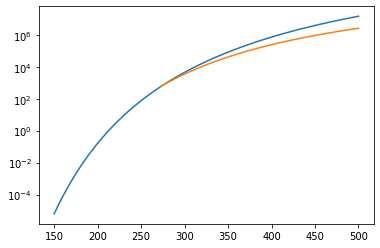

In [ ]:
plt.semilogy(Tsat_ice, psat_ice)
plt.semilogy(Tsat_lv, psat_lv)

# Compute e, v, s for each temperature region

# Region I+V (T < T_n)

# Region T == T_n

# Region V+L (T > T_n)


In [ ]:
p_n, T_n

(611.657, 273.16)

In [ ]:
# Pure S, L, V specifics
s_s_n = IAPWS_ice.s_iceI(p_n, T_n)
u_s_n = IAPWS_ice.u_iceI(p_n, T_n)
rho_s_n = IAPWS_ice.rho_iceI(p_n, T_n)
v_s_n = 1 / rho_s_n
s_l_n, h_l_n, u_l_n, w_l_n = [float(out) for out in all_pure_lv(rhol_n, T_n)]
s_v_n, h_v_n, u_v_n, w_v_n = [float(out) for out in all_pure_lv(rhov_n, T_n)]
v_l_n = 1 / rhol_n
v_v_n = 1 / rhov_n

In [ ]:
# Linear system: pick two among
# y_s * u_s + y_l * u_l + (1 - y_s - y_l) * u_v = u
# y_s * s_s + y_l * s_l + (1 - y_s - y_l) * s_v = s
# y_s * v_s + y_l * v_l + (1 - y_s - y_l) * v_v = v

# Matrix form
def sl_fractions(u,v):
  ''' Compute [y_s, y_l] for given u, v of mixture at triple point. '''
  _A = np.array([[u_s_n - u_v_n, u_l_n - u_v_n],
                [v_s_n - v_v_n, v_l_n - v_v_n]])
  _b = np.array([u - u_v_n, v - v_v_n])
  # Explicit inverse
  _det = (_A[0,0] * _A[1,1] - _A[0,1] * _A[1,0])
  _Ainvb = np.array([_A[1,1] * _b[0] - _A[0,1] * _b[1],
                  -_A[1,0] * _b[0] + _A[0,0] * _b[1]]) / _det
  return _Ainvb

def sl_uv(y_s, y_l):
  ''' Compute [u, v] for given [y_s, y_l] of mixture at triple point. '''
  _Ay = np.array([y_s * u_s_n + y_l * u_l_n + (1 - y_s - y_l) * u_v_n,
                  y_s * v_s_n + y_l * v_l_n + (1 - y_s - y_l) * v_v_n])
  return _Ay

# y_s_range = np.linspace(0, 1.0, 201)
# y_l_range = np.linspace(0, 1.0, 401)

# Parametrize using y_cond and z_s, where y_s = z_s * y_cond
y_cond_range = np.unique([
                         *np.linspace(0, 1 - 3e-2, 600),
                         *np.sort(1 - np.geomspace(1e-13, 3e-2, 301, endpoint=False)),
                         ])
z_s_range = np.linspace(0, 1.0, 101)

mg_y_cond, mg_z_s = np.meshgrid(y_cond_range, z_s_range)
mg_u_SLV = np.zeros_like(mg_y_cond)
mg_v_SLV = np.zeros_like(mg_y_cond)

for i in range(mg_y_cond.shape[0]):
  for j in range(mg_z_s.shape[1]):
    y_cond, z_s = mg_y_cond[i,j], mg_z_s[i,j]
    y_s, y_l = z_s * y_cond, (1.0 - z_s) * y_cond
    mg_u_SLV[i,j], mg_v_SLV[i,j] = sl_uv(y_s, y_l)

In [ ]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import three_state_eos
model = three_state_eos.Model()
# model.boundary_L_LS()

Populating LSV
Populating LV
Populating SV
Populating LS
Populating L
Populating V
Init done


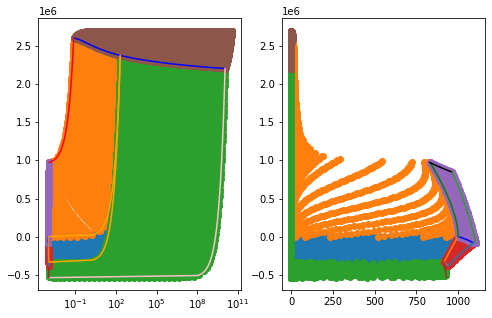

In [ ]:
plt.figure(figsize=(8,5))
plt.subplot(1,2,1)
plt.semilogx()
plt.scatter(model.LSV.v, model.LSV.u)
plt.scatter(model.LV.v, model.LV.u)
plt.scatter(model.SV.v, model.SV.u)
plt.scatter(model.LS.v, model.LS.u)
plt.scatter(model.L.v, model.L.u)
plt.scatter(model.V.v, model.V.u)

plt.semilogx(LV_vl_range, LV_ul_range, 'b')
plt.plot(v_lv_range, u_lv_range, 'orange')
plt.semilogx(1 / SV_rhov_range, SV_uv_range, 'b')
plt.plot(v_T_MIN_curve, u_T_MIN_curve, 'pink')
plt.semilogx(1 / SV_rhos_range, SV_us_range, 'brown')
plt.semilogx(v_ls_range, u_ls_range, 'orange')
plt.plot(T_MAX_curve_v, T_MAX_curve_u, 'red')
plt.semilogx(1 / LS_rhov_range, LS_uv_range, 'b')
plt.semilogx(1 / LS_rhos_range, LS_us_range, 'grey')
plt.plot(LS_Tmin_v, LS_Tmin_u)
plt.plot(LS_Tn_v, LS_Tn_u)

plt.subplot(1,2,2)
plt.scatter(1/model.LSV.v, model.LSV.u)
plt.scatter(1/model.LV.v, model.LV.u)
plt.scatter(1/model.SV.v, model.SV.u)
plt.scatter(1/model.LS.v, model.LS.u)
plt.scatter(1/model.L.v, model.L.u)
plt.scatter(1/model.V.v, model.V.u)

plt.plot(LS_rhov_range, LS_uv_range, 'b')
plt.plot(LS_rhos_range, LS_us_range, 'grey')
plt.plot(1/LS_Tmin_v, LS_Tmin_u)
plt.plot(1/LS_Tn_v, LS_Tn_u)
plt.plot(L_bdry_rhol_sat, L_bdry_ul, 'g')
plt.plot(LTMAX_rhol_range, LTMAX_u, 'k')
plt.plot(bdry_rho_pmax, bdry_u_pmax)
plt.plot(SV_rhos_range, SV_us_range, 'brown')


(-200000.0, 400000.0)

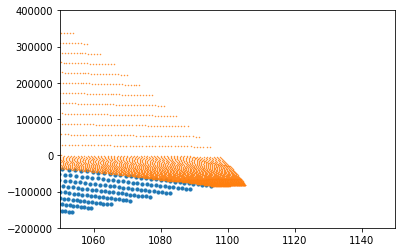

In [ ]:
plt.scatter(1/model.LS.v, model.LS.u, s=10)
plt.scatter(1/model.L.v, model.L.u, s=.2)
plt.xlim(1050, 1150)
plt.ylim(-.2e6, .4e6)

In [ ]:
IAPWS_ice.ice_I_melting_p(T_I_min)

209898499.84752092

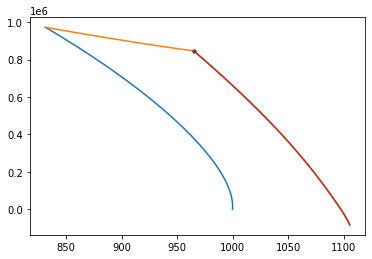

In [ ]:
# L (purple)

# Saturation curve
L_bdry_T_range = np.linspace(T_n, T_MAX, 100)
L_bdry_rhol_sat = np.zeros_like(L_bdry_T_range)
L_bdry_ul = np.zeros_like(L_bdry_T_range)
for i, T in enumerate(L_bdry_T_range):
  L_bdry_rhol_sat[i] = iapws95_light.prho_sat(T)["rho_satl"]
  L_bdry_ul[i] = all_pure_lv(L_bdry_rhol_sat[i], T)[2]
plt.plot(L_bdry_rhol_sat, L_bdry_ul)

LTMAX_rhol_max = three_state_eos.SL_rhol(P_MAX, T_MAX, init=820, num_newton_iter=8, verbose=False)

assert(T_MAX < iapws95_light.Tc)
p_T_MAX = iapws95_light.prho_sat(T_MAX)["psat"]
LTMAX_rhol_min = iapws95_light.prho_sat(T_MAX)["rho_satl"]

LTMAX_rhol_range = np.linspace(LTMAX_rhol_min, LTMAX_rhol_max, 100)
LTMAX_u = np.zeros_like(LTMAX_rhol_range)
for i, rhol in enumerate(LTMAX_rhol_range):
  LTMAX_u[i] = all_pure_lv(rhol, T_MAX)[2]
plt.plot(LTMAX_rhol_range, LTMAX_u)
plt.plot(LTMAX_rhol_range[-1], LTMAX_u[-1], 'k.')

# Use max pressure based on lowest temperature T_LS_min
bdry_T_range = np.linspace(T_LS_min, T_MAX, 100)
bdry_rho_pmax = np.zeros_like(bdry_T_range)
bdry_u_pmax = np.zeros_like(bdry_T_range)
for i, T in enumerate(bdry_T_range):
  # Density using max pressure from chosen validity range
  bdry_rho_pmax[i] = three_state_eos.SL_rhol(P_MAX, T, num_newton_iter=20, init=1000, verbose=False)
  bdry_u_pmax[i] = float(all_pure_lv(bdry_rho_pmax[i], T)[2])

plt.plot(bdry_rho_pmax, bdry_u_pmax)


In [ ]:
three_state_eos.SL_rhol(P_MAX, 553.16, num_newton_iter=10, verbose=True, init=1000)

[937.34865195] [4.73297182e+08]
[925.08175549] [2.81654212e+08]
[924.63605318] [2.51072626e+08]
[924.63547731] [2.50001382e+08]
[924.6354773] [2.5e+08]
[924.6354773] [2.5e+08]
[924.6354773] [2.5e+08]
[924.6354773] [2.5e+08]
[924.6354773] [2.5e+08]
[924.6354773] [2.5e+08]


924.6354773048365

In [ ]:
IAPWS_ice.ice_I_melting_p(T_LS_min), P_MAX

(218725763.4623685, 250000000.0)

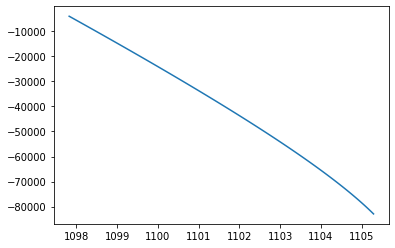

In [ ]:


# LPMAX_rhol_max = three_state_eos.SL_rhol(p_Lmax, T_I_min, init=909.22, num_newton_iter=8, verbose=False)
# LPMAX_rhol_max
# P_MAX = IAPWS_ice.ice_I_melting_p(T_I_min)
# assert(T_MAX < iapws95_light.Tc)
# p_T_MAX = iapws95_light.prho_sat(T_MAX)["psat"]
# LTMAX_rhol_min = iapws95_light.prho_sat(T_MAX)["rho_satl"]

# LTMAX_rhol_range = np.linspace(LTMAX_rhol_min, LTMAX_rhol_max, 100)
# LTMAX_u = np.zeros_like(LTMAX_rhol_range)
# for i, rhol in enumerate(LTMAX_rhol_range):
#   LTMAX_u[i] = all_pure_lv(rhol, T_MAX)[2]
# plt.plot(1/LTMAX_rhol_range, LTMAX_u)

In [ ]:
model.L.p.shape

(100, 62)

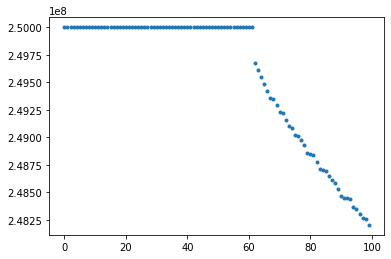

In [ ]:
plt.plot(np.sort(model.L.p.ravel())[::-1][:100], '.')

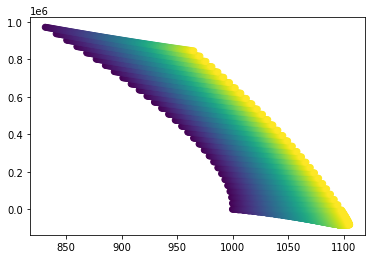

In [ ]:
plt.scatter(1/model.L.v, model.L.u, c=model.L.p)

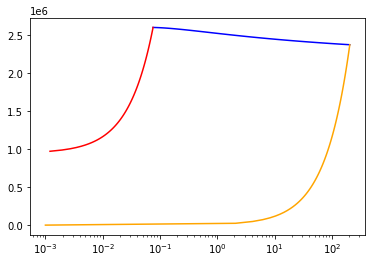

In [ ]:
# Compute pure vapor over T range


boundary_Vsat_T_range = np.linspace(T_n, T_MAX, 100)
LV_ul_range = np.zeros_like(boundary_Vsat_T_range)
LV_vl_range = np.zeros_like(boundary_Vsat_T_range)
for i, T in enumerate(boundary_Vsat_T_range):
  sat_triple = iapws95_light.prho_sat(T)
  _, rhol, rhov = sat_triple["psat"], sat_triple["rho_satl"], sat_triple["rho_satv"]
  s_v, h_v, u_v, w_v = [float(out) for out in all_pure_lv(rhov, T)]

  LV_ul_range[i] = u_v
  LV_vl_range[i] = 1/rhov

# Compute max T curve
LV_Tmax_y_l_range = np.linspace(0, 1, 100)
sat_triple_Tmax = iapws95_light.prho_sat(T_MAX)
_, rhol, rhov = sat_triple_Tmax["psat"], sat_triple_Tmax["rho_satl"], sat_triple_Tmax["rho_satv"]

s_l_Tmax, h_l_Tmax, u_l_Tmax, w_l_Tmax = [float(out) for out in all_pure_lv(rhol, T_MAX)]
s_v_Tmax, h_v_Tmax, u_v_Tmax, w_v_Tmax = [float(out) for out in all_pure_lv(rhov, T_MAX)]

LV_Tmax_u = LV_Tmax_y_l_range * u_l_Tmax + (1 - LV_Tmax_y_l_range) * u_v_Tmax
LV_Tmax_v = LV_Tmax_y_l_range / rhol + (1 - LV_Tmax_y_l_range) / rhov

# V-LV boundary
y_l_pure_range = np.linspace(0, 1, 100)
v_lv_range = (v_l_n * y_l_pure_range + v_v_n * (1 - y_l_pure_range))
u_lv_range = (u_l_n * y_l_pure_range + u_v_n * (1 - y_l_pure_range))
plt.semilogx(LV_vl_range, LV_ul_range, 'b')
plt.plot(v_lv_range, u_lv_range, 'orange')


T_MAX_curve_y_l_range = np.linspace(0, 1, 100)
T_MAX_curve_u = np.zeros_like(T_MAX_curve_y_l_range)
T_MAX_curve_v = np.zeros_like(T_MAX_curve_y_l_range)
sat_triple = iapws95_light.prho_sat(T_MAX)
_, rhol, rhov = sat_triple["psat"], sat_triple["rho_satl"], sat_triple["rho_satv"]
s_l, h_l, u_l, w_l = [float(out) for out in all_pure_lv(rhol, T_MAX)]
s_v, h_v, u_v, w_v = [float(out) for out in all_pure_lv(rhov, T_MAX)]
for i, y_l in enumerate(T_MAX_curve_y_l_range):

  T_MAX_curve_u[i] = y_l * u_l + (1.0 - y_l) * u_v
  T_MAX_curve_v[i] = y_l / rhol + (1.0 - y_l) / rhov

# T_MAX curve
plt.plot(T_MAX_curve_v, T_MAX_curve_u, 'red')


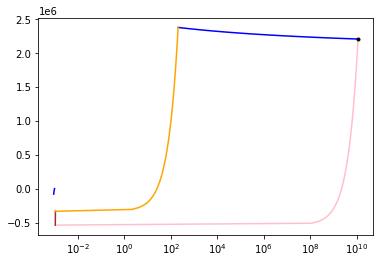

In [ ]:
# Compute pure vapor at all temperatures
_SV_T_range = np.linspace(T_MIN, T_n, 101)
SV_rhov_range = np.array([
  three_state_eos.SV_rhov(IAPWS_ice.ice_I_sublimation_p(T), T)
  for T in _SV_T_range])
SV_uv_range = np.array([float(all_pure_lv(rhov, T)[2])
  for rhov, T in zip(SV_rhov_range, _SV_T_range)])
plt.semilogx(1 / SV_rhov_range, SV_uv_range, 'b')

# Compute min temperature at all ice-vapor fractions

SV_y_s_range_reparam = np.linspace(0, 1, 100)
p_MIN = IAPWS_ice.ice_I_sublimation_p(T_MIN)
u_s_TMIN = IAPWS_ice.u_iceI(p_MIN, T_MIN)
rho_s_TMIN = IAPWS_ice.rho_iceI(p_MIN, T_MIN)

rhov_MIN = three_state_eos.SV_rhov(p_MIN, T_MIN)
s_v_TMIN, h_v_TMIN, u_v_TMIN, w_v_TMIN = [float(out) for out in all_pure_lv(rhov_MIN, T_MIN)]

u_T_MIN_curve = SV_y_s_range_reparam * u_s_TMIN + (1 - SV_y_s_range_reparam) * u_v_TMIN
v_T_MIN_curve = SV_y_s_range_reparam / rho_s_TMIN + (1 - SV_y_s_range_reparam) / rhov_MIN

# SV_uv_range
plt.plot(v_T_MIN_curve, u_T_MIN_curve, 'pink')

plt.plot(v_T_MIN_curve[0], u_T_MIN_curve[0], 'k.')
v_T_MIN_curve[0], u_T_MIN_curve[0], 1 / SV_rhov_range[0], SV_uv_range[0]

# Compute pure solid at all temperatures
SV_rhos_range = np.array([IAPWS_ice.rho_iceI(IAPWS_ice.ice_I_sublimation_p(T), T)
                          for T in _SV_T_range])
SV_us_range = np.array([IAPWS_ice.u_iceI(IAPWS_ice.ice_I_sublimation_p(T), T)
                        for T in _SV_T_range])
plt.semilogx(1 / SV_rhos_range, SV_us_range, 'brown')

y_s_pure_range = np.linspace(0, 1, 100)
v_ls_range = (v_s_n * y_s_pure_range + v_v_n * (1 - y_s_pure_range))
u_ls_range = (u_s_n * y_s_pure_range + u_v_n * (1 - y_s_pure_range))
plt.semilogx(v_ls_range, u_ls_range, 'orange')


SyntaxError: 'return' outside function (2935761495.py, line 45)

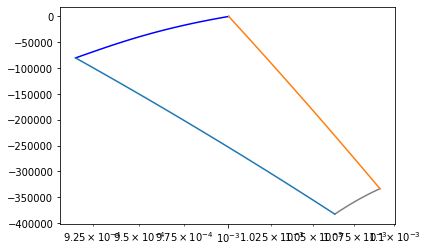

In [ ]:
# LS boundaries

# Pure L
_LS_T_range = np.linspace(T_I_min, T_n, 101)
LS_rhol_range = np.array([
  three_state_eos.SL_rhol(IAPWS_ice.ice_I_melting_p(T), T)
  for T in _LS_T_range])
LS_uv_range = np.array([float(all_pure_lv(rhov, T)[2])
  for rhov, T in zip(LS_rhol_range, _LS_T_range)])
# Pure S
p_melt_curve = IAPWS_ice.ice_I_melting_p(_LS_T_range)
LS_us_range = np.array([
  IAPWS_ice.u_iceI(p,T) for p, T in zip(p_melt_curve, _LS_T_range)])
LS_rhos_range = np.array([
  IAPWS_ice.rho_iceI(p,T) for p, T in zip(p_melt_curve, _LS_T_range)])

plt.semilogx(1 / LS_rhol_range, LS_uv_range, 'b')
plt.semilogx(1 / LS_rhos_range, LS_us_range, 'grey')

# T_I_min boundary

LS_y_l_range = np.linspace(0, 1, 100)
LS_Tmin_u = np.zeros_like(LS_y_l_range)
LS_Tmin_v = np.zeros_like(LS_y_l_range)
LS_Tn_u = np.zeros_like(LS_y_l_range)
LS_Tn_v =np.zeros_like(LS_y_l_range)

rhol_T_min = three_state_eos.SL_rhol(IAPWS_ice.ice_I_melting_p(T_I_min), T_I_min)
rhol_T_n = three_state_eos.SL_rhol(IAPWS_ice.ice_I_melting_p(T_n), T_n)
ul_T_min = float(all_pure_lv(rhol_T_min, T_I_min)[2])
ul_T_n = float(all_pure_lv(rhol_T_n, T_n)[2])
rhos_T_n = IAPWS_ice.rho_iceI(IAPWS_ice.ice_I_melting_p(T_n), T_n)
rhos_T_min = IAPWS_ice.rho_iceI(IAPWS_ice.ice_I_melting_p(T_I_min), T_I_min)
us_T_n = IAPWS_ice.u_iceI(IAPWS_ice.ice_I_melting_p(T_n), T_n)
us_T_min = IAPWS_ice.u_iceI(IAPWS_ice.ice_I_melting_p(T_I_min), T_I_min)
for i, y_l in enumerate(LS_y_l_range):
  LS_Tmin_u[i] = y_l * ul_T_min + (1.0 - y_l) * us_T_min
  LS_Tmin_v[i] = y_l / rhol_T_min + (1.0 - y_l) / rhos_T_min
  LS_Tn_u[i] = y_l * ul_T_n + (1.0 - y_l) * us_T_n
  LS_Tn_v[i] = y_l / rhol_T_n + (1.0 - y_l) / rhos_T_n

plt.plot(LS_Tmin_v, LS_Tmin_u)
plt.plot(LS_Tn_v, LS_Tn_u)

return
# Compute min temperature at all ice-vapor fractions

SV_y_s_range_reparam = np.linspace(0, 1, 100)
p_MIN = IAPWS_ice.ice_I_sublimation_p(T_MIN)
u_s_TMIN = IAPWS_ice.u_iceI(p_MIN, T_MIN)
rho_s_TMIN = IAPWS_ice.rho_iceI(p_MIN, T_MIN)

rhov_MIN = three_state_eos.SV_rhov(p_MIN, T_MIN)
s_v_TMIN, h_v_TMIN, u_v_TMIN, w_v_TMIN = [float(out) for out in all_pure_lv(rhov_MIN, T_MIN)]

u_T_MIN_curve = SV_y_s_range_reparam * u_s_TMIN + (1 - SV_y_s_range_reparam) * u_v_TMIN
v_T_MIN_curve = SV_y_s_range_reparam / rho_s_TMIN + (1 - SV_y_s_range_reparam) / rhov_MIN

# SV_uv_range
plt.plot(v_T_MIN_curve, u_T_MIN_curve, 'pink')

plt.plot(v_T_MIN_curve[0], u_T_MIN_curve[0], 'k.')
v_T_MIN_curve[0], u_T_MIN_curve[0], 1 / SV_rhov_range[0], SV_uv_range[0]

# Compute pure solid at all temperatures
SV_rhos_range = np.array([IAPWS_ice.rho_iceI(IAPWS_ice.ice_I_sublimation_p(T), T)
                          for T in _SV_T_range])
SV_us_range = np.array([IAPWS_ice.u_iceI(IAPWS_ice.ice_I_sublimation_p(T), T)
                        for T in _SV_T_range])
plt.semilogx(1 / SV_rhos_range, SV_us_range, 'brown')

y_s_pure_range = np.linspace(0, 1, 100)
v_ls_range = (v_s_n * y_s_pure_range + v_v_n * (1 - y_s_pure_range))
u_ls_range = (u_s_n * y_s_pure_range + u_v_n * (1 - y_s_pure_range))
plt.semilogx(v_ls_range, u_ls_range, 'orange')

In [ ]:
# Boundary identification (Parametrization e(v))
# 1. Gas saturation curve e(log v)


# 2. LV-SLV e(log v)
# 3. SLV-SV e(log v)
# 4. L-LV e(rho) purple-orange
# 5. L-LS e(rho) red-purple
# 6. SLV-LS red-blue
# 7. SL-SV red-green

# 8. SV-Tmin (green bottom)
# 9. V-Tmin (brown top?)

In [ ]:
rho_test = np.array([13.198906510099981, 13.198906510099981])
u_test = np.array([2602522.75447951, 2602522.75447951])

_rho_test_vec = np.concatenate((1/np.geomspace(1/800, 1e10, 200),
                                np.linspace(800, 1100, 1600)))
_u_test_vec = np.linspace(-.6e6, 3e6, 801)
_rho_mg, _u_mg = np.meshgrid(_rho_test_vec, _u_test_vec)
rho_test = _rho_mg.ravel()
u_test = _u_mg.ravel()

# Test point on boundary
rho_scalar = 13.198906510099981
u_scalar = 2602522.75447951

In [ ]:
no_boundary = three_state_eos.Boundary(np.array([0, 1]), np.array([0, 1]), -1, 1)
def const_true(rho, u):
  if type(rho) is float or type(rho) is int:
    return True
  else:
      return np.full(rho.shape, True)
no_boundary.over = const_true
no_boundary.under = const_true

# Table: Under & Over then Region
region_definitions = [
  # Upper and lower conditions
  (model.boundaries.LS_T_I_MIN, model.boundaries.L_LS, "LS"),
  (model.boundaries.LS_T_I_MIN, model.boundaries.LS_LSV, "LS"),
  (model.boundaries.S_LS, model.boundaries.LS_LSV, "LS"),
  (model.boundaries.SV_TMIN, model.boundaries.S_SV, "SV"),
  (model.boundaries.SV_TMIN, model.boundaries.SV_LSV, "SV"),
  (model.boundaries.SV_TMIN, model.boundaries.V_SV, "SV"),
  (model.boundaries.LV_LSV, model.boundaries.L_LV_normal, "LV"),
  (model.boundaries.L_LV_anomal, model.boundaries.L_LV_normal, "LV"),
  (model.boundaries.LV_LSV, model.boundaries.LV_TMAX, "LV"),
  (model.boundaries.LV_LSV, model.boundaries.V_LV, "LV"),
  (model.boundaries.LS_LSV, model.boundaries.LV_LSV, "LSV"),
  (model.boundaries.SV_LSV, model.boundaries.LV_LSV, "LSV"),
  # L region is overlapping with LV region a bit
  # Order matters: L here assumes no membership in LV
  # Strictly, the L region should divide L_LS into rho < rho_max(L_LV_anomal)
  # and rho > rho_max(L_LV_anomal)
  (model.boundaries.L_LV_normal, model.boundaries.L_TMAX, "L"),
  (model.boundaries.L_LV_normal, model.boundaries.L_PMAX, "L"),
  (model.boundaries.L_LS, model.boundaries.L_LV_anomal, "L"),
  (model.boundaries.L_LS, model.boundaries.L_PMAX, "L"),
  # Mono condition
  (model.boundaries.V_LV, no_boundary, "V"),
  (model.boundaries.V_SV, no_boundary, "V"),
  (model.boundaries.LV_TMAX, no_boundary, "LV_EXTRAPOLATE"),
]

# Out of range 
# (all_true, all_true "default")

# Array of labels
labels = np.array([region[2] for region in region_definitions],
                  dtype=object)
# num -> str representation of region labels
label_str_by_index: np.array = np.unique([*labels, "DEFAULT"])
# str -> num representation of region labels
label_index_by_str: dict = {
  name: index for index, name in enumerate(label_str_by_index)
}

In [ ]:
# Find first region where membership, else label as "default"
# In the case where multiple are true, only the first region is used as label
membership_values = np.array([
  region[0].under(rho_test, u_test)
  & region[1].over(rho_test, u_test)
  for region in region_definitions])

# Count # memberships (should be 1, or 0 if out of zone, and possibly 2+ exactly on boundaries)
membership_count = membership_values.sum(axis=0)
# Extract region label, excluding default
region_labels = labels[membership_values.argmax(axis=0)]
# Add default case
region_labels = np.where(membership_count >= 1, region_labels, "DEFAULT")
# Convert to numeric
region_labels_numeric = np.array([label_index_by_str[l] for l in region_labels])

array([242465, 244265, 246065, 247865, 249665, 251465, 253265],
      dtype=int64)

Distribution of regions (including DEFAULT) for test range


array(['DEFAULT', 'L', 'LS', 'LSV', 'LV', 'LV+', 'LV_EXTRAPOLATE', 'SV',
       'V'], dtype='<U14')

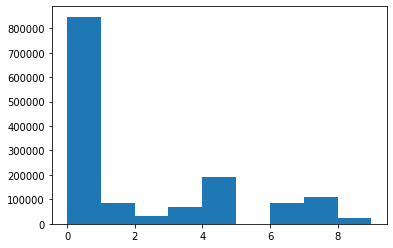

In [ ]:
# plt.hist(region_labels_numeric, np.arange(7))
plt.hist(region_labels_numeric, np.arange(len(label_str_by_index) + 1))
print("Distribution of regions (including DEFAULT) for test range")
label_str_by_index

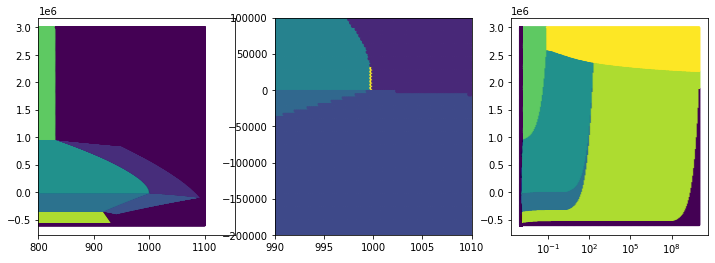

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.scatter(rho_test, u_test, s=1.3, c=region_labels_numeric)
plt.xlim(left=800)

# Highlight anomalous zone
color_data = region_labels_numeric.copy()
color_data[np.where(membership_values[7,:])] = region_labels_numeric.max() + 1
plt.subplot(1,3,2)
focus_window = (rho_test > 990) & (rho_test < 1010)
plt.scatter(rho_test[focus_window], u_test[focus_window], s=10, c=color_data[focus_window])
plt.xlim(990, 1010)
plt.ylim(-.2e6, .1e6)

plt.subplot(1,3,3)
plt.scatter(1/rho_test, u_test, s=1.3, c=region_labels_numeric)
plt.xscale('log')

In [ ]:
model = three_state_eos.Model()

Populating LSV
Populating LV
Populating SV
Populating LS
Populating L
Populating V
Populating boundaries
Init done


In [ ]:
np.concatenate(glob_v)

array([2.05991225e+02, 2.05657651e+02, 2.05324078e+02, ...,
       8.97932033e-02, 8.24305282e-02, 7.57638520e-02])

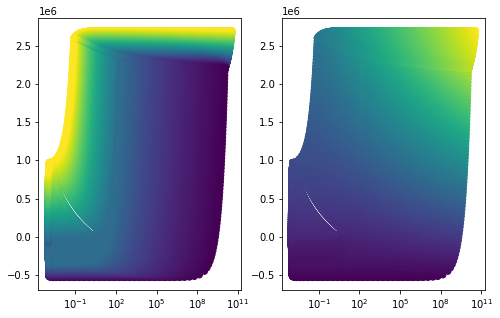

In [ ]:
plt.figure(figsize=(8,5))


# All-region concatenation
model_regions = [model.LSV, model.LV, model.SV, model.LS, model.L, model.V]
vuspT = [(region.v.ravel(),
          region.u.ravel(),
          region.s.ravel(),
          region.p.ravel(),
          region.T.ravel())
       for region in model_regions]
glob_v, glob_u, glob_s, glob_p, glob_T = zip(*vuspT)

plt.subplot(1,2,1)
plt.semilogx()
plt.scatter(np.concatenate(glob_v),
            np.concatenate(glob_u),
            c=np.concatenate(glob_T))

plt.subplot(1,2,2)
plt.semilogx()
plt.scatter(np.concatenate(glob_v),
            np.concatenate(glob_u),
            c=np.concatenate(glob_s))

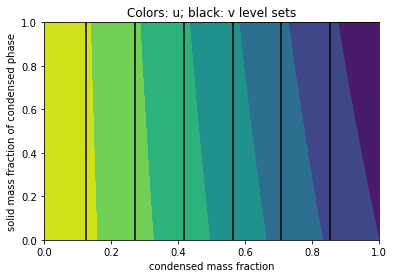

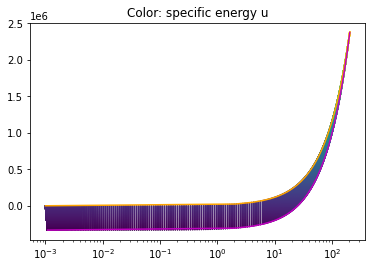

In [ ]:
plt.contourf(mg_y_cond, mg_z_s, mg_u_SLV)
plt.contour(mg_y_cond, mg_z_s, mg_v_SLV, colors='k')
plt.title("Colors: u; black: v level sets")

plt.xlabel("condensed mass fraction")
plt.ylabel("solid mass fraction of condensed phase")

plt.figure()
plt.semilogx()
plt.scatter(mg_v_SLV.ravel(), mg_u_SLV.ravel(), c=mg_u_SLV.ravel(), s=0.2)
plt.title("Color: specific energy u")

# LV boundary (top)
y_l_pure_range = np.linspace(0, 1, 100)
v_lv_range = (v_l_n * y_l_pure_range + v_v_n * (1 - y_l_pure_range))
u_lv_range = (u_l_n * y_l_pure_range + u_v_n * (1 - y_l_pure_range))
plt.plot(v_lv_range, u_lv_range, 'orange')

# SV boundary (bottom)
y_s_pure_range = np.linspace(0, 1, 100)
v_sv_range = (v_s_n * y_s_pure_range + v_v_n * (1 - y_s_pure_range))
u_sv_range = (u_s_n * y_s_pure_range + u_v_n * (1 - y_s_pure_range))
plt.plot(v_sv_range, u_sv_range, 'm')

In [ ]:
# Populate LV region
# LV_y_l_range = np.linspace(0, 1, 51)
LV_y_l_range = np.unique([
                         *np.linspace(0, 1 - 3e-2, 40),
                         *np.sort(1 - np.geomspace(1e-13, 3e-2, 21, endpoint=False)),
                         ])
LV_T_range = np.linspace(T_n, T_MAX, 101)

mg_LV_y_l, mg_LV_T = np.meshgrid(LV_y_l_range, LV_T_range)
mg_u_LV = np.zeros_like(mg_LV_y_l)
mg_v_LV = np.zeros_like(mg_LV_y_l)
mg_p = np.zeros_like(mg_LV_y_l)
for i in range(mg_LV_y_l.shape[0]):
  for j in range(mg_LV_T.shape[1]):
    y_l, T = mg_LV_y_l[i,j], mg_LV_T[i,j]
    sat_triple = iapws95_light.prho_sat(T)
    mg_p[i,j], rhol, rhov = sat_triple["psat"], sat_triple["rho_satl"], sat_triple["rho_satv"]

    s_l, h_l, u_l, w_l = [float(out) for out in all_pure_lv(rhol, T)]
    s_v, h_v, u_v, w_v = [float(out) for out in all_pure_lv(rhov, T)]

    mg_u_LV[i,j] = y_l * u_l + (1 - y_l) * u_v
    mg_v_LV[i,j] = y_l / rhol + (1 - y_l) / rhov

In [ ]:
# Compute pure vapor over T range
LV_ul_range = np.zeros_like(LV_T_range)
LV_vl_range = np.zeros_like(LV_T_range)
for i, T in enumerate(LV_T_range):
  sat_triple = iapws95_light.prho_sat(T)
  _, rhol, rhov = sat_triple["psat"], sat_triple["rho_satl"], sat_triple["rho_satv"]
  s_v, h_v, u_v, w_v = [float(out) for out in all_pure_lv(rhov, T)]

  LV_ul_range[i] = u_v
  LV_vl_range[i] = 1/rhov

# Compute max T curve
LV_Tmax_y_l_range = np.linspace(0, 1, 100)
sat_triple_Tmax = iapws95_light.prho_sat(T_MAX)
_, rhol, rhov = sat_triple_Tmax["psat"], sat_triple_Tmax["rho_satl"], sat_triple_Tmax["rho_satv"]

s_l_Tmax, h_l_Tmax, u_l_Tmax, w_l_Tmax = [float(out) for out in all_pure_lv(rhol, T_MAX)]
s_v_Tmax, h_v_Tmax, u_v_Tmax, w_v_Tmax = [float(out) for out in all_pure_lv(rhov, T_MAX)]

LV_Tmax_u = LV_Tmax_y_l_range * u_l_Tmax + (1 - LV_Tmax_y_l_range) * u_v_Tmax
LV_Tmax_v = LV_Tmax_y_l_range / rhol + (1 - LV_Tmax_y_l_range) / rhov

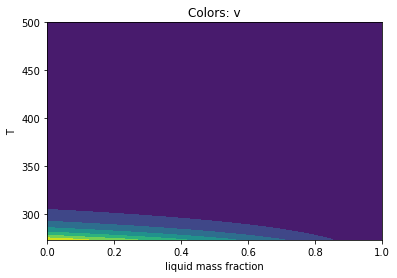

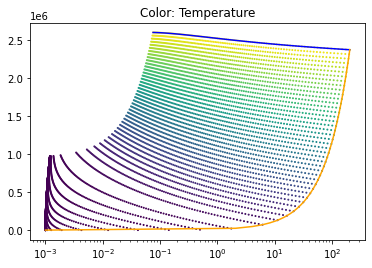

In [ ]:
plt.contourf(mg_LV_y_l, mg_LV_T, mg_v_LV)
plt.title("Colors: v")
plt.xlabel("liquid mass fraction")
plt.ylabel("T")

plt.figure()
plt.semilogx()
plt.scatter(mg_v_LV.ravel(), mg_u_LV.ravel(), c=1-mg_LV_y_l.ravel(), s=1)
plt.title("Color: Temperature")

# LV boundary
y_l_pure_range = np.linspace(0, 1, 100)

v_lv_range = (v_l_n * y_l_pure_range + v_v_n * (1 - y_l_pure_range))
u_lv_range = (u_l_n * y_l_pure_range + u_v_n * (1 - y_l_pure_range))
plt.plot(LV_vl_range, LV_ul_range, 'b')
plt.plot(v_lv_range, u_lv_range, 'orange')

In [ ]:
def SV_rhov(p_target, T, num_newton_iter=4):
  ''' Return density of vapor at solid-vapor saturation curve. '''
  # Initial guess: ideal gas approx
  rho_v = p_target / (iapws95_light.R * T)
  for i in range(num_newton_iter):
    # Compute potential and derivatives at guessed rho_v and temperature T
    s_v, h_v, u_v, w_v, _potential = all_pure_lv(rho_v, T, dump=True)
    d = rho_v / iapws95_light.rhoc
    # Compute pressure
    p = (1 + d * _potential["phir_d"]) * rho_v * iapws95_light.R * T
    dpdd = iapws95_light.rhoc * iapws95_light.R * T * (
      1 + d * d * _potential["phir_dd"] + 2 * d * _potential["phir_d"]
    )
    rho_v += iapws95_light.rhoc * (p_target - p) / dpdd
  return float(rho_v)

from numpy.polynomial import Polynomial

def SL_rhol(p_target, T, num_newton_iter=4, verbose=False, init=None):
  ''' Return density of liquid at solid-liquid saturation curve. '''
  # Static initial guess curve
  init_curve = Polynomial(np.array([1058.05940709,  -43.85534939, 
                                    -10.44251961,   -3.67634714]),
                          domain=[250, 273.16])
 
  
  if init is None:
    # Initial guess: normal liquid density
    rho_l = init_curve(T)
  else:
    rho_l = init
  for i in range(num_newton_iter):
    # Compute potential and derivatives at guessed rho_l and temperature T
    _, _, _, _, _potential = all_pure_lv(rho_l, T, dump=True)
    d = rho_l / iapws95_light.rhoc
    # Compute pressure
    p = (1 + d * _potential["phir_d"]) * rho_l * iapws95_light.R * T
    dpdd = iapws95_light.rhoc * iapws95_light.R * T * (
      1 + d * d * _potential["phir_dd"] + 2 * d * _potential["phir_d"]
    )
    rho_l += iapws95_light.rhoc * (p_target - p) / dpdd
    if verbose:
      print(rhol,p)
  return float(rho_l)

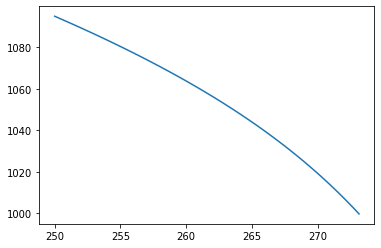

In [ ]:
_T_test = np.linspace(250, 273.16, 100)
_p_test = IAPWS_ice.ice_I_melting_p(_T_test)
rhol_test = np.zeros_like(_T_test)

for i in range(len(_p_test)):
  rhol_test[i] = SL_rhol(_p_test[i], _T_test[i], num_newton_iter=5, verbose=False)

plt.plot(_T_test, rhol_test)


In [ ]:
# Populate SV region
SV_y_s_range = np.unique([
                         *np.linspace(0, 1 - 3e-2, 60),
                         *np.sort(1 - np.geomspace(1e-13, 3e-2, 31, endpoint=False)),
                         ])
SV_T_range = np.linspace(T_MIN, T_n, 51)
mg_SV_y_s, mg_SV_T = np.meshgrid(SV_y_s_range, SV_T_range)
mg_u_SV = np.zeros_like(mg_SV_y_s)
mg_v_SV = np.zeros_like(mg_SV_y_s)
mg_p_SV = np.zeros_like(mg_SV_y_s)
for i in range(mg_SV_y_s.shape[0]):
  for j in range(mg_SV_T.shape[1]):
    y_s, T = mg_SV_y_s[i,j], mg_SV_T[i,j]

    mg_p_SV[i,j] = IAPWS_ice.ice_I_sublimation_p(T)

    u_s = IAPWS_ice.u_iceI(mg_p_SV[i,j], T)
    rho_s = IAPWS_ice.rho_iceI(mg_p_SV[i,j], T)

    rhov = SV_rhov(mg_p_SV[i,j], T)
    s_v, h_v, u_v, w_v = [float(out) for out in all_pure_lv(rhov, T)]

    mg_u_SV[i,j] = y_s * u_s + (1 - y_s) * u_v
    mg_v_SV[i,j] = y_s / rho_s + (1 - y_s) / rhov

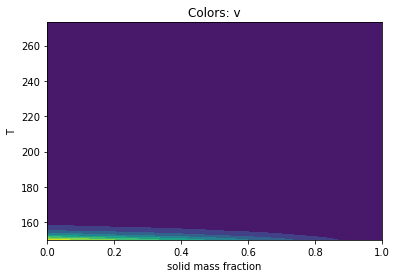

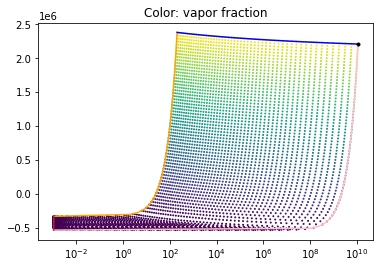

In [ ]:
plt.contourf(mg_SV_y_s, mg_SV_T, mg_v_SV)
plt.title("Colors: v")
plt.xlabel("solid mass fraction")
plt.ylabel("T")

plt.figure()
plt.scatter(mg_v_SV.ravel(), mg_u_SV.ravel(), c=1-mg_SV_y_s.ravel(), s=1)
plt.title("Color: vapor fraction")

# LS boundary
y_s_pure_range = np.linspace(0, 1, 100)
v_ls_range = (v_s_n * y_s_pure_range + v_v_n * (1 - y_s_pure_range))
u_ls_range = (u_s_n * y_s_pure_range + u_v_n * (1 - y_s_pure_range))
plt.semilogx(v_ls_range, u_ls_range, 'orange')

# Compute pure vapor at all temperatures
SV_rhov_range = np.array([SV_rhov(IAPWS_ice.ice_I_sublimation_p(T), T)
                          for T in SV_T_range])
SV_uv_range = np.array([float(all_pure_lv(rhov, T)[2])
                        for rhov, T in zip(SV_rhov_range, SV_T_range)])
plt.semilogx(1 / SV_rhov_range, SV_uv_range, 'b')

# Compute min temperature at all ice-vapor fractions

SV_y_s_range_reparam = np.linspace(0, 1, 100)
p_MIN = IAPWS_ice.ice_I_sublimation_p(T_MIN)
u_s_TMIN = IAPWS_ice.u_iceI(p_MIN, T_MIN)
rho_s_TMIN = IAPWS_ice.rho_iceI(p_MIN, T_MIN)

rhov_MIN = SV_rhov(p_MIN, T_MIN)
s_v_TMIN, h_v_TMIN, u_v_TMIN, w_v_TMIN = [float(out) for out in all_pure_lv(rhov_MIN, T_MIN)]

u_T_MIN_curve = SV_y_s_range_reparam * u_s_TMIN + (1 - SV_y_s_range_reparam) * u_v_TMIN
v_T_MIN_curve = SV_y_s_range_reparam / rho_s_TMIN + (1 - SV_y_s_range_reparam) / rhov_MIN

# SV_uv_range
plt.plot(v_T_MIN_curve, u_T_MIN_curve, 'pink')

plt.plot(v_T_MIN_curve[0], u_T_MIN_curve[0], 'k.')
v_T_MIN_curve[0], u_T_MIN_curve[0], 1 / SV_rhov_range[0], SV_uv_range[0]

# Compute pure solid at all temperatures
SV_rhos_range = np.array([IAPWS_ice.rho_iceI(IAPWS_ice.ice_I_sublimation_p(T), T)
                          for T in SV_T_range])
SV_us_range = np.array([IAPWS_ice.u_iceI(IAPWS_ice.ice_I_sublimation_p(T), T)
                        for T in SV_T_range])
plt.semilogx(1 / SV_rhos_range, SV_us_range, 'brown')

In [ ]:
IAPWS_ice.ice_I_melting_p()
IAPWS_ice.T 

-852696529.4880499

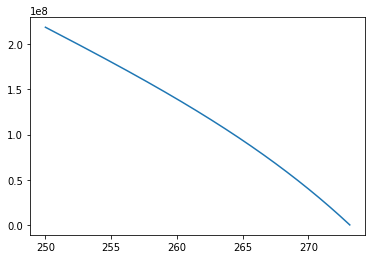

In [ ]:
T_test_range = np.linspace(250, T_n, 1009)
plt.plot(T_test_range,
         IAPWS_ice.ice_I_melting_p(T_test_range))

In [ ]:
# Populate SL region
T_LS_min = 250

SL_y_s_range = np.linspace(0, 1, 30)
SL_T_range = np.linspace(T_LS_min, T_n, 51)
mg_SL_y_s, mg_SL_T = np.meshgrid(SL_y_s_range, SL_T_range)
mg_u_SL = np.zeros_like(mg_SL_y_s)
mg_v_SL = np.zeros_like(mg_SL_y_s)
mg_p_SL = np.zeros_like(mg_SL_y_s)
for i in range(mg_SL_y_s.shape[0]):
  for j in range(mg_SL_T.shape[1]):
    y_s, T = mg_SL_y_s[i,j], mg_SL_T[i,j]

    mg_p_SL[i,j] = IAPWS_ice.ice_I_melting_p(T)

    u_s = IAPWS_ice.u_iceI(mg_p_SL[i,j], T)
    rho_s = IAPWS_ice.rho_iceI(mg_p_SL[i,j], T)

    rhol = SL_rhol(mg_p_SL[i,j], T)
    s_l, h_l, u_l, w_l = [float(out) for out in all_pure_lv(rhol, T)]

    mg_u_SL[i,j] = y_s * u_s + (1 - y_s) * u_l
    mg_v_SL[i,j] = y_s / rho_s + (1 - y_s) / rhol

In [ ]:
mg_p_SL.min(), mg_p_SL.max()

(611.657, 218725763.4623685)

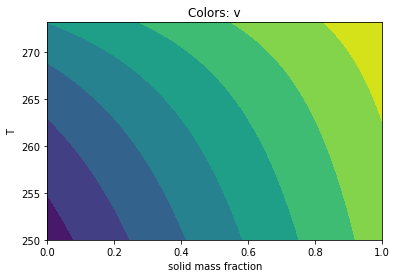

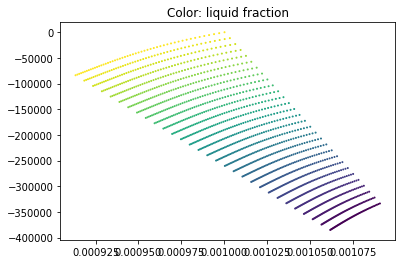

In [ ]:
plt.contourf(mg_SL_y_s, mg_SL_T, mg_v_SL)
plt.title("Colors: v")
plt.xlabel("solid mass fraction")
plt.ylabel("T")

plt.figure()
plt.scatter(mg_v_SL.ravel(), mg_u_SL.ravel(), c=1-mg_SL_y_s.ravel(), s=1)
plt.title("Color: liquid fraction")

# LS boundary
y_s_pure_range = np.linspace(0, 1, 100)
v_ls_range = (v_s_n * y_s_pure_range + v_v_n * (1 - y_s_pure_range))
u_ls_range = (u_s_n * y_s_pure_range + u_v_n * (1 - y_s_pure_range))

# Compute pure vapor at all temperatures
SV_rhov_range = np.array([SV_rhov(IAPWS_ice.ice_I_sublimation_p(T), T)
                          for T in SV_T_range])
SV_uv_range = np.array([float(all_pure_lv(rhov, T)[2])
                        for rhov, T in zip(SV_rhov_range, SV_T_range)])

# Compute min temperature at all ice-vapor fractions

SV_y_s_range_reparam = np.linspace(0, 1, 100)
p_MIN = IAPWS_ice.ice_I_sublimation_p(T_MIN)
u_s_TMIN = IAPWS_ice.u_iceI(p_MIN, T_MIN)
rho_s_TMIN = IAPWS_ice.rho_iceI(p_MIN, T_MIN)

rhov_MIN = SV_rhov(p_MIN, T_MIN)
s_v_TMIN, h_v_TMIN, u_v_TMIN, w_v_TMIN = [float(out) for out in all_pure_lv(rhov_MIN, T_MIN)]

u_T_MIN_curve = SV_y_s_range_reparam * u_s_TMIN + (1 - SV_y_s_range_reparam) * u_v_TMIN
v_T_MIN_curve = SV_y_s_range_reparam / rho_s_TMIN + (1 - SV_y_s_range_reparam) / rhov_MIN

# SV_uv_range

v_T_MIN_curve[0], u_T_MIN_curve[0], 1 / SV_rhov_range[0], SV_uv_range[0]

# Compute pure solid at all temperatures
SV_rhos_range = np.array([IAPWS_ice.rho_iceI(IAPWS_ice.ice_I_sublimation_p(T), T)
                          for T in SV_T_range])
SV_us_range = np.array([IAPWS_ice.u_iceI(IAPWS_ice.ice_I_sublimation_p(T), T)
                        for T in SV_T_range])

(0.00020034108366447076, 10000.0)

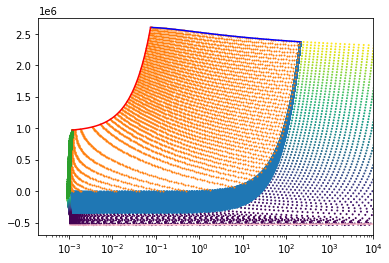

In [ ]:
plt.semilogx()
plt.scatter(mg_v_SV.ravel(), mg_u_SV.ravel(), c=1-mg_SV_y_s.ravel(), s=1)
plt.scatter(mg_v_SLV.ravel(), mg_u_SLV.ravel(), s=1)
plt.scatter(mg_v_LV.ravel(), mg_u_LV.ravel(), s=1)
plt.scatter(mg_v_SL.ravel(), mg_u_SL.ravel(), c=1-mg_SL_y_s.ravel(), s=1)
plt.scatter(1 / L_mg_rho.ravel(), L_mg_u.ravel(), s=1)

plt.plot(v_T_MIN_curve, u_T_MIN_curve, 'pink')
plt.plot(LV_vl_range, LV_ul_range, 'b')
plt.plot(LV_Tmax_v, LV_Tmax_u, 'r')
plt.xlim(right = 1e4)

In [ ]:
T_I_min

251.165

In [ ]:
L_T_range_sub = np.linspace(T_LS_min, T_n, 31, endpoint=False)
L_T_range_sup = np.linspace(T_n, T_MAX, 31)


In [ ]:

# Minimum pressure for liquid from melting curve


In [ ]:
sat_triple = iapws95_light.prho_sat(T)
sat_triple["rho_satl"]

{'psat': array([579.23714944]),
 'rho_satl': 999.7366092332034,
 'rho_satv': 0.0046098017580315466}

In [ ]:
P_MAX = 250e6

# Temperature range below the triple point
rho_low_L_sub = np.zeros_like(L_T_range_sub)
rho_high_L_sub = np.zeros_like(L_T_range_sub)
for i, T in enumerate(L_T_range_sub):
  # Minimum pressure for liquid from melting curve
  rho_low_L_sub[i] = SL_rhol(IAPWS_ice.ice_I_melting_p(T), T, num_newton_iter=20, verbose=False)
  # Max pressure from chosen validity range
  rho_high_L_sub[i] = SL_rhol(P_MAX, T, num_newton_iter=20, verbose=False)

# Temperature range above the triple point
rho_low_L_sup = np.zeros_like(L_T_range_sup)
rho_high_L_sup = np.zeros_like(L_T_range_sup)
for i, T in enumerate(L_T_range_sup):
  # Minimum pressure for liquid from liquid-vapor saturation curve
  sat_triple = iapws95_light.prho_sat(T)
  rho_low_L_sup[i] = sat_triple["rho_satl"]
  # Max pressure from chosen validity range
  rho_high_L_sup[i] = SL_rhol(P_MAX, T, num_newton_iter=20, verbose=False, init=1000)

# Fuse T array
L_T_range_all = ((*L_T_range_sub, *L_T_range_sup))
rho_temp = np.zeros((100,))
L_mg_T, L_mg_rho = np.meshgrid(L_T_range_all, rho_temp)
# Replace L_mg values with non-Cartesian
for i, T in enumerate(L_T_range_sub):
  L_mg_rho[:,i] = np.linspace(rho_low_L_sub[i], rho_high_L_sub[i], len(rho_temp))

for i, T in enumerate(L_T_range_sup):
  L_mg_rho[:,i+len(L_T_range_sub)] = np.linspace(rho_low_L_sup[i], rho_high_L_sup[i], len(rho_temp))

In [ ]:
# Fill L state behavior
L_mg_s = np.zeros_like(L_mg_rho)
L_mg_h = np.zeros_like(L_mg_rho)
L_mg_u = np.zeros_like(L_mg_rho)
L_mg_w = np.zeros_like(L_mg_rho)
for i, (T, rho) in enumerate(zip(L_mg_T.ravel(), L_mg_rho.ravel())):
  L_mg_s.ravel()[i], L_mg_h.ravel()[i], L_mg_u.ravel()[i], L_mg_w.ravel()[i] = \
    [float(out) for out in all_pure_lv(rho, T)]

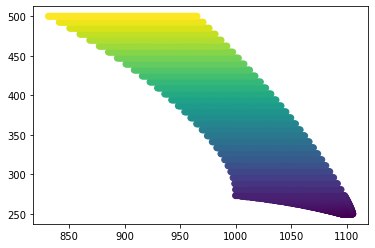

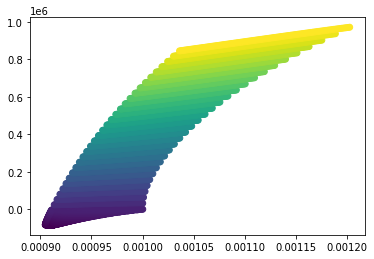

In [ ]:
plt.figure()
plt.scatter(L_mg_rho.ravel(), L_mg_T.ravel(), c=L_mg_u)
plt.figure()
plt.scatter(1/L_mg_rho.ravel(), L_mg_u.ravel(), c=L_mg_T)


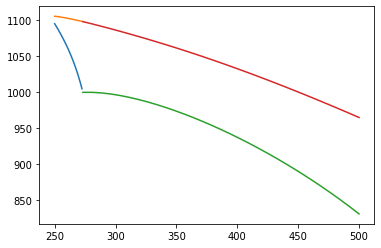

In [ ]:
plt.plot(L_T_range_sub, rho_low_L_sub)
plt.plot(L_T_range_sub, rho_high_L_sub)
plt.plot(L_T_range_sup, rho_low_L_sup)
plt.plot(L_T_range_sup, rho_high_L_sup)

In [ ]:
# Stencil grid


In [ ]:
# Populate L region 
L_y_s_range = np.unique([
                         *np.linspace(0, 1 - 3e-2, 60),
                         *np.sort(1 - np.geomspace(1e-13, 3e-2, 31, endpoint=False)),
                         ])
L_T_range = np.linspace(T_MIN, T_n, 51)
mg_SV_y_s, mg_SV_T = np.meshgrid(SV_y_s_range, SV_T_range)
mg_u_SV = np.zeros_like(mg_SV_y_s)
mg_v_SV = np.zeros_like(mg_SV_y_s)
mg_p_SV = np.zeros_like(mg_SV_y_s)
for i in range(mg_SV_y_s.shape[0]):
  for j in range(mg_SV_T.shape[1]):
    y_s, T = mg_SV_y_s[i,j], mg_SV_T[i,j]

    mg_p_SV[i,j] = IAPWS_ice.ice_I_sublimation_p(T)

    u_s = IAPWS_ice.u_iceI(mg_p_SV[i,j], T)
    rho_s = IAPWS_ice.rho_iceI(mg_p_SV[i,j], T)

    rhov = SV_rhov(mg_p_SV[i,j], T)
    s_v, h_v, u_v, w_v = [float(out) for out in all_pure_lv(rhov, T)]

    mg_u_SV[i,j] = y_s * u_s + (1 - y_s) * u_v
    mg_v_SV[i,j] = y_s / rho_s + (1 - y_s) / rhov

(0.00020034108366447076, 0.01)

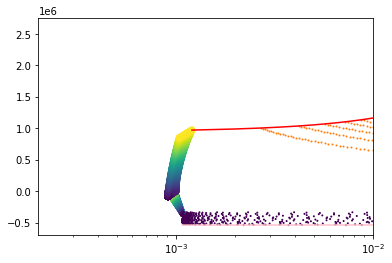

In [ ]:
plt.semilogx()
plt.scatter(mg_v_SV.ravel(), mg_u_SV.ravel(), c=1-mg_SV_y_s.ravel(), s=1)
plt.scatter(mg_v_SLV.ravel(), mg_u_SLV.ravel(), s=1)
plt.scatter(mg_v_LV.ravel(), mg_u_LV.ravel(), s=1)
plt.scatter(mg_v_SL.ravel(), mg_u_SL.ravel(), c=1-mg_SL_y_s.ravel(), s=1)
plt.scatter(1/L_mg_rho.ravel(), L_mg_u.ravel(), c=L_mg_T)

plt.plot(v_T_MIN_curve, u_T_MIN_curve, 'pink')
plt.plot(LV_vl_range, LV_ul_range, 'b')
plt.plot(LV_Tmax_v, LV_Tmax_u, 'r')
plt.xlim(right = 1e-2)

In [ ]:
# Pure liquid phase

(1.967211954630585e-11, 10000.0)

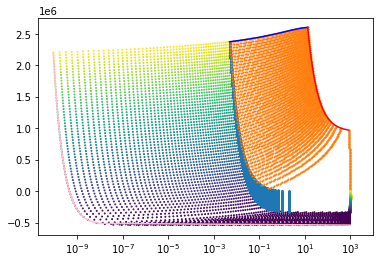

In [ ]:
plt.semilogx()
plt.scatter(1/mg_v_SV.ravel(), mg_u_SV.ravel(), c=1-mg_SV_y_s.ravel(), s=1)
plt.scatter(1/mg_v_SLV.ravel(), mg_u_SLV.ravel(), s=1)
plt.scatter(1/mg_v_LV.ravel(), mg_u_LV.ravel(), s=1)
plt.scatter(1/mg_v_SL.ravel(), mg_u_SL.ravel(), c=1-mg_SL_y_s.ravel(), s=1)

plt.plot(1/v_T_MIN_curve, u_T_MIN_curve, 'pink')
plt.plot(1/LV_vl_range, LV_ul_range, 'b')
plt.plot(1/LV_Tmax_v, LV_Tmax_u, 'r')
plt.xlim(right = 1e4)

(500.0, 1149.6745315617093)

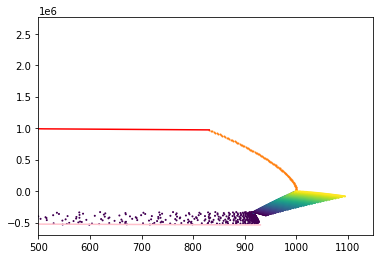

In [ ]:
plt.scatter(1/mg_v_SV.ravel(), mg_u_SV.ravel(), c=1-mg_SV_y_s.ravel(), s=1)
plt.scatter(1/mg_v_SLV.ravel(), mg_u_SLV.ravel(), s=1)
plt.scatter(1/mg_v_LV.ravel(), mg_u_LV.ravel(), s=1)
plt.scatter(1/mg_v_SL.ravel(), mg_u_SL.ravel(), c=1-mg_SL_y_s.ravel(), s=1)

plt.plot(1/v_T_MIN_curve, u_T_MIN_curve, 'pink')
plt.plot(1/LV_vl_range, LV_ul_range, 'b')
plt.plot(1/LV_Tmax_v, LV_Tmax_u, 'r')
plt.xlim(left=.5e3)

In [ ]:
rho_low_sub = IAPWS_ice.ice_I_sublimation_p(T_range_sub)
rho_low_sub
T_range_sub

array([150.        , 153.97290323, 157.94580645, 161.91870968,
       165.8916129 , 169.86451613, 173.83741935, 177.81032258,
       181.78322581, 185.75612903, 189.72903226, 193.70193548,
       197.67483871, 201.64774194, 205.62064516, 209.59354839,
       213.56645161, 217.53935484, 221.51225806, 225.48516129,
       229.45806452, 233.43096774, 237.40387097, 241.37677419,
       245.34967742, 249.32258065, 253.29548387, 257.2683871 ,
       261.24129032, 265.21419355, 269.18709677])

In [ ]:
P_MIN = p_MIN

In [ ]:
T_range_sub = np.linspace(T_MIN, T_n, 21, endpoint=False)
T_range_sup = np.linspace(T_n, T_MAX, 21)
N_rho = 301

# Compute liquid density bounds for temperature range below triple point
rho_low_sub = np.zeros_like(T_range_sub)
rho_high_sub = np.zeros_like(T_range_sub)
for i, T in enumerate(T_range_sub):
  # Minimum pressure for liquid from melting curve
  rho_low_sub[i] = SV_rhov(p_MIN, T, num_newton_iter=20)
  # Max pressure from chosen validity range
  rho_high_sub[i] = SV_rhov(IAPWS_ice.ice_I_sublimation_p(T), T,
                            num_newton_iter=20)

# Compute liquid density bounds for temperature range above triple point
rho_low_sup = np.zeros_like(T_range_sup)
rho_high_sup = np.zeros_like(T_range_sup)
for i, T in enumerate(T_range_sup):
  # Minimum pressure for liquid from melting curve
  rho_low_sup[i] = SV_rhov(p_MIN, T, num_newton_iter=20)
  # Minimum pressure for liquid from liquid-vapor saturation curve
  sat_triple = iapws95_light.prho_sat(T)
  rho_high_sup[i] = sat_triple["rho_satv"]

# Fuse T array
T_range_all = ((*T_range_sub, *T_range_sup))
# Construct temperature and density sample values (non-Cartesian)
rho_temp = np.zeros((N_rho,))
mg_T, mg_rho = np.meshgrid(T_range_all, rho_temp)
# Replace values with non-Cartesian
for i, T in enumerate(T_range_sub):
  mg_rho[:,i] = np.geomspace(rho_low_sub[i], rho_high_sub[i], len(rho_temp))
for i, T in enumerate(T_range_sup):
  mg_rho[:,i+len(T_range_sub)] = np.geomspace(rho_low_sup[i], rho_high_sup[i], len(rho_temp))

# Compute thermodynamic variables for each pair (rho, T)
mg_s = np.zeros_like(mg_T)
mg_u = np.zeros_like(mg_T)
mg_p = np.zeros_like(mg_T)
for i, (rho, T) in enumerate(zip(mg_rho.ravel(), mg_T.ravel())):
  s, h, u, w, potentials = all_pure_lv(rho, T, dump=True)
  mg_p.ravel()[i] = rho * iapws95_light.R * T * (
    1 + rho / iapws95_light.rhoc * potentials["phir_d"])
  mg_s.ravel()[i], mg_u.ravel()[i] = s, u

# return SimpleNamespace(
#   u=mg_u, v=1/mg_rho, s=mg_s, p=mg_p, T=mg_T,
#   y_l=np.ones_like(mg_T),
#   y_s=np.zeros_like(mg_T),
#   y_v=np.zeros_like(mg_T),
#   )

plt.semilogy(T_range_sub, rho_low_sub)
plt.semilogy(T_range_sub, rho_high_sub)
plt.semilogy(T_range_sup, rho_low_sup)
plt.semilogy(T_range_sup, rho_high_sup)


SyntaxError: 'return' outside function (1563742195.py, line 46)

In [ ]:
mg_rho.shape, mg_u.shape

((100, 62), (100, 62))

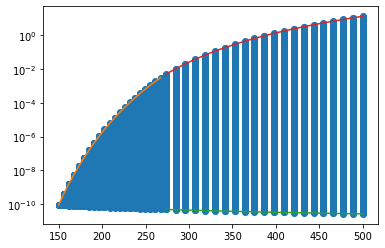

In [ ]:
plt.semilogy(T_range_sub, rho_low_sub)
plt.semilogy(T_range_sub, rho_high_sub)
plt.semilogy(T_range_sup, rho_low_sup)
plt.semilogy(T_range_sup, rho_high_sup)

plt.scatter(mg_T.ravel(), mg_rho.ravel())


In [ ]:
mg_rho[0,:]

array([8.87974337e-11, 8.65062279e-11, 8.43302861e-11, 8.22611240e-11,
       8.02910697e-11, 7.84131692e-11, 7.66211043e-11, 7.49091214e-11,
       7.32719699e-11, 7.17048483e-11, 7.02033573e-11, 6.87634587e-11,
       6.73814388e-11, 6.60538765e-11, 6.47776153e-11, 6.35497378e-11,
       6.23675439e-11, 6.12285306e-11, 6.01303745e-11, 5.90709161e-11,
       5.80481452e-11, 5.70601886e-11, 5.61052985e-11, 5.51818421e-11,
       5.42882925e-11, 5.34232199e-11, 5.25852843e-11, 5.17732287e-11,
       5.09858722e-11, 5.02221049e-11, 4.94808823e-11, 4.87612207e-11,
       4.74478191e-11, 4.62033156e-11, 4.50224275e-11, 4.39003985e-11,
       4.28329351e-11, 4.18161513e-11, 4.08465217e-11, 3.99208405e-11,
       3.90361858e-11, 3.81898895e-11, 3.73795095e-11, 3.66028070e-11,
       3.58577254e-11, 3.51423722e-11, 3.44550030e-11, 3.37940072e-11,
       3.31578955e-11, 3.25452887e-11, 3.19549077e-11, 3.13855644e-11,
       3.08361540e-11, 3.03056478e-11, 2.97930865e-11, 2.92975748e-11,
      

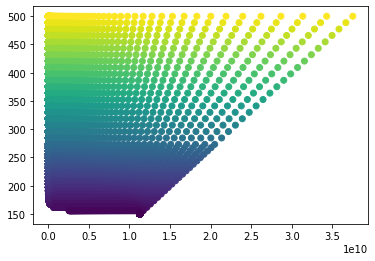

In [ ]:
plt.scatter(1/mg_rho.ravel(), mg_T.ravel(), c=mg_T.ravel())

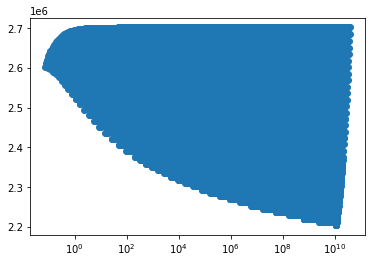

In [ ]:
plt.semilogx()
plt.scatter(1/mg_rho.ravel(), mg_u.ravel())
i = 0
# plt.scatter(1/mg_rho[i,:], mg_u[i,:], c=mg_p[i,:])


#### Interpolator dev

In [1159]:
model.label_str_by_index

array(['DEFAULT', 'L', 'LS', 'LSV', 'LV', 'LV_EXTRAPOLATE', 'SV', 'V'],
      dtype='<U14')

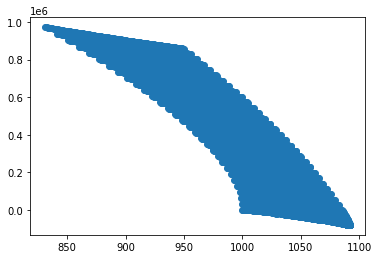

In [ ]:
plt.scatter(1/model.L.v, model.L.u)

region = model.L
# (rho, u) coordinate
# rbfi = scipy.interpolate.RBFInterpolator(
#   np.stack((1/region.v.ravel(),
#           region.u.ravel()), axis=-1),
#   np.stack((region.T.ravel(),
#             region.p.ravel(),
#             region.s.ravel(),
#             region.y_l.ravel(),
#             region.y_s.ravel(),), axis=-1)
# )
rbfi = scipy.interpolate.RBFInterpolator(
  np.stack((1/region.v.ravel(),
          region.u.ravel()), axis=1),
  np.stack((region.T.ravel(),
            region.p.ravel(),
            region.s.ravel(),
            region.y_l.ravel(),
            region.y_s.ravel(),), axis=1), neighbors=10,
)

In [ ]:
model.interpolators[1](np.array([[1e4, 2e5]]))

array([[ 3.26089333e+02, -8.86477243e+09,  4.10060788e+03,
         1.00000000e+00,  0.00000000e+00]])

In [1186]:
model.label_str_by_index

array(['DEFAULT', 'L', 'LS', 'LSV', 'LV', 'LV_EXTRAPOLATE', 'SV', 'V'],
      dtype='<U14')

In [ ]:
region_labels_numeric.max()


In [ ]:
# Replace interpolators

# self = model
# self.interpolators = [scipy.interpolate.LinearNDInterpolator(
#         np.stack((1/self.region_mapping[name].v.ravel(),
#                 self.region_mapping[name].u.ravel()), axis=1),
#         np.stack((self.region_mapping[name].T.ravel(),
#                   self.region_mapping[name].p.ravel(),
#                   self.region_mapping[name].s.ravel(),
#                   self.region_mapping[name].y_l.ravel(),
#                   self.region_mapping[name].y_s.ravel(),), axis=1),
#         # neighbors=3,
#       ) for name in self.label_str_by_index]

# for name in self.label_str_by_index:
#   print(name)
#   scipy.interpolate.LinearNDInterpolator(
#     np.stack((1/self.region_mapping[name].v.ravel(),
#             self.region_mapping[name].u.ravel()), axis=1),
#     np.stack((self.region_mapping[name].T.ravel(),
#               self.region_mapping[name].p.ravel(),
#               self.region_mapping[name].s.ravel(),
#               self.region_mapping[name].y_l.ravel(),
#               self.region_mapping[name].y_s.ravel(),), axis=1),
#     # neighbors=3,
#   )

DEFAULT
L
LS
LSV
LV
LV_EXTRAPOLATE
SV
V


In [1478]:
_rho_test_vec = np.concatenate((1/np.geomspace(1/800, 1e10, 200),
                                np.linspace(800, 1100, 300)))
_u_test_vec = np.linspace(-.6e6, 3e6, 200)
_rho_mg, _u_mg = np.meshgrid(_rho_test_vec, _u_test_vec)
rho_test = _rho_mg.ravel()
u_test = _u_mg.ravel()

In [1475]:
model.label_str_by_index

array(['DEFAULT', 'L', 'LS', 'LSV', 'LV', 'LV_EXTRAPOLATE', 'SV', 'V'],
      dtype='<U14')

In [1486]:
# Interpoalte
# Partition interpolators
region_labels, region_labels_numeric = \
  model.identify_regions(rho_test, u_test)

out = np.full((len(rho_test), 5), np.nan)
for i, name in enumerate(model.label_str_by_index):
  if name == "DEFAULT" or name == "LV_EXTRAPOLATE":
    continue
  if name != "LV":
    continue
  # Compute indices where label is i
  partition = np.where(region_labels_numeric == i)[0]
  # Use appropriate interpolant for region (T, p, s, y_l, y_s)
  out[partition, :] = model.interpolators[i](
    np.stack((rho_test[partition], u_test[partition],), axis=-1)
  )

In [1451]:
out.shape

(100000, 5)

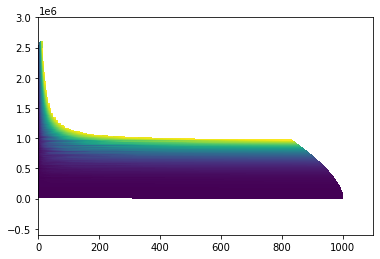

In [1487]:
plt.contourf(_rho_mg, _u_mg, np.reshape(out[:,1], _rho_mg.shape), levels=1000)

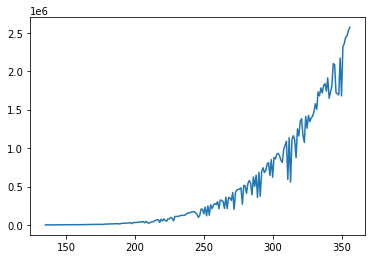

In [1488]:
plt.plot(np.reshape(out[:,1], _rho_mg.shape)[:,5])

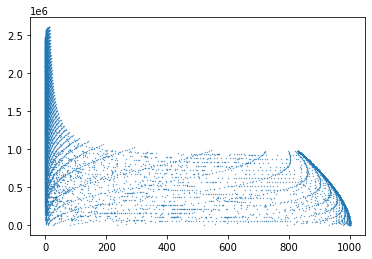

In [1485]:
plt.scatter(1/model.LV.v, model.LV.u, s=0.1)

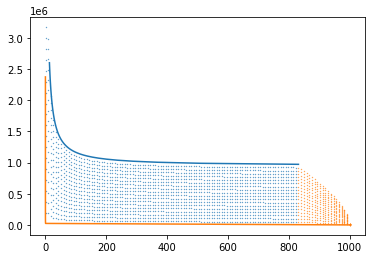

In [1402]:
# Improving point density in LV region
plt.plot(model.boundaries.LV_TMAX.rho,
         model.boundaries.LV_TMAX.u)
plt.plot(model.boundaries.LV_LSV.rho,
         model.boundaries.LV_LSV.u)

# Add between LV_LVS and LV_TMAX
fill_range_rho = np.linspace(1, model.boundaries.LV_TMAX.rho_R, 100)[:-1]
dummy_range_u = np.zeros((20,))
mg_rho, mg_u = np.meshgrid(fill_range_rho, dummy_range_u, indexing="ij")

for i in range(fill_range_rho.size):
  mg_u[i,:] = np.linspace(
    model.boundaries.LV_LSV.interpolator(fill_range_rho[i]), 
    model.boundaries.LV_TMAX.interpolator(fill_range_rho[i]),
    dummy_range_u.size)

# Additional point coordinates
add1_rho, add1_u = mg_rho[:,1:-1].flatten(), mg_u[:,1:-1].flatten()

# Add between LV_LVS and L_LV
fill_range_rho = np.linspace(model.boundaries.L_LV_normal.rho_L,
                             model.boundaries.L_LV_normal.rho_R, 20)
dummy_range_u = np.zeros((20,))
mg_rho, mg_u = np.meshgrid(fill_range_rho, dummy_range_u, indexing="ij")

for i in range(fill_range_rho.size):
  mg_u[i,:] = np.linspace(
    model.boundaries.LV_LSV.interpolator(fill_range_rho[i]), 
    model.boundaries.L_LV_normal.interpolator(fill_range_rho[i]),
    dummy_range_u.size)

# Additional point coordinates
add2_rho, add2_u = mg_rho[:,1:-1].flatten(), mg_u[:,1:-1].flatten()

new_rho = np.concatenate((add1_rho, add2_rho))
new_u = np.concatenate((add1_u, add2_u))

plt.scatter(add1_rho, add1_u, s=0.1)
plt.scatter(add2_rho, add2_u, s=0.1)

In [1418]:
# Obtain origin coordinates (y_l, T) in LV region
computed = model.interpolators[model.label_index_by_str["LV"]](
  np.stack((new_rho, new_u), axis=1))
T, p, s, y_l, y_s = computed.T
T_target = T[np.where(~np.isnan(T))]
y_l_target = y_l[np.where(~np.isnan(T))]
p_computed = np.zeros_like(T_target)
u_computed = np.zeros_like(T_target)
v_computed = np.zeros_like(T_target)
s_computed = np.zeros_like(T_target)

# Native computation from (y_l, T) coordinates
for i in range(T_target.size):
  T = T_target[i]
  y_l = y_l_target[i]
  sat_triple = iapws95_light.prho_sat(T)
  p_computed[i], rhol, rhov = (sat_triple["psat"],
                            sat_triple["rho_satl"],
                            sat_triple["rho_satv"])
  s_l, h_l, u_l, w_l = all_pure_lv(rhol, T)
  s_v, h_v, u_v, w_v = all_pure_lv(rhov, T)

  u_computed[i] = y_l * u_l + (1 - y_l) * u_v
  v_computed[i] = y_l / rhol + (1 - y_l) / rhov
  s_computed[i] = y_l * s_l + (1 - y_l) * s_v

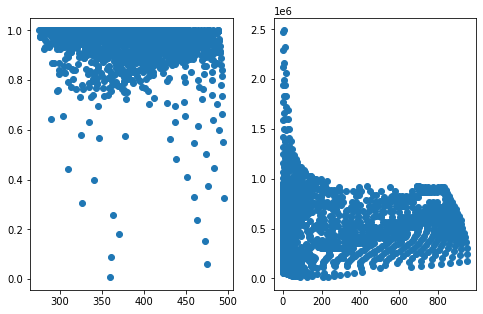

In [1421]:
plt.figure(figsize=(8,5))
plt.subplot(1,2,1)
plt.scatter(T_target, y_l_target)
plt.subplot(1,2,2)
plt.scatter(1/v_computed, u_computed)

In [1424]:


def regrid_LV(interpolator:callable,
              left_range_rho_resolution=100,
              right_range_rho_resolution=20,
              u_resolution=20):
  ''' Uses given interpolator to estimate grid in LV region
  Used to fix skinny triangle problem in LV region
  '''
  
  # Set fill points between LV_LVS and LV_TMAX
  fill_range_rho = np.linspace(1, model.boundaries.LV_TMAX.rho_R,
                              left_range_rho_resolution)[:-1]
  dummy_range_u = np.zeros((u_resolution,))
  mg_rho, mg_u = np.meshgrid(fill_range_rho, dummy_range_u, indexing="ij")
  # Interpolate range between top and bottom boundaries u(rho)
  for i in range(fill_range_rho.size):
    mg_u[i,:] = np.linspace(
      model.boundaries.LV_LSV.interpolator(fill_range_rho[i]), 
      model.boundaries.LV_TMAX.interpolator(fill_range_rho[i]),
      dummy_range_u.size)
  # Additional point coordinates
  add1_rho, add1_u = mg_rho[:,1:-1].flatten(), mg_u[:,1:-1].flatten()

  # Add between LV_LVS and L_LV
  fill_range_rho = np.linspace(model.boundaries.L_LV_normal.rho_L,
                              model.boundaries.L_LV_normal.rho_R,
                              right_range_rho_resolution)
  dummy_range_u = np.zeros((u_resolution,))
  mg_rho, mg_u = np.meshgrid(fill_range_rho, dummy_range_u, indexing="ij")
  # Interpolate range between top and bottom boundaries u(rho)
  for i in range(fill_range_rho.size):
    mg_u[i,:] = np.linspace(
      model.boundaries.LV_LSV.interpolator(fill_range_rho[i]), 
      model.boundaries.L_LV_normal.interpolator(fill_range_rho[i]),
      dummy_range_u.size)
  # Additional point coordinates
  add2_rho, add2_u = mg_rho[:,1:-1].flatten(), mg_u[:,1:-1].flatten()

  # Obtain origin coordinates (y_l, T) in LV region
  computed = interpolator(
    np.stack((np.concatenate((add1_rho, add2_rho)),
              np.concatenate((add1_u, add2_u))), axis=1))

  # Native computation from (y_l, T) coordinates
  T, p, s, y_l, y_s = computed.T
  T_target = T[np.where(~np.isnan(T))]
  y_l_target = y_l[np.where(~np.isnan(T))]
  p_computed = np.zeros_like(T_target)
  u_computed = np.zeros_like(T_target)
  v_computed = np.zeros_like(T_target)
  s_computed = np.zeros_like(T_target)
  for i in range(T_target.size):
    T = T_target[i]
    y_l = y_l_target[i]
    sat_triple = iapws95_light.prho_sat(T)
    p_computed[i], rhol, rhov = (sat_triple["psat"],
                              sat_triple["rho_satl"],
                              sat_triple["rho_satv"])
    s_l, h_l, u_l, w_l = all_pure_lv(rhol, T)
    s_v, h_v, u_v, w_v = all_pure_lv(rhov, T)

    u_computed[i] = y_l * u_l + (1 - y_l) * u_v
    v_computed[i] = y_l / rhol + (1 - y_l) / rhov
    s_computed[i] = y_l * s_l + (1 - y_l) * s_v

  return (v_computed, u_computed, T_target, p_computed, s_computed,
          y_l_target, np.zeros_like(y_l_target))

In [1464]:
v_base = model.LV.v
u_base = model.LV.u
T_base = model.LV.T
p_base = model.LV.p
s_base = model.LV.s
y_l_base = model.LV.y_l
y_s_base = model.LV.y_s



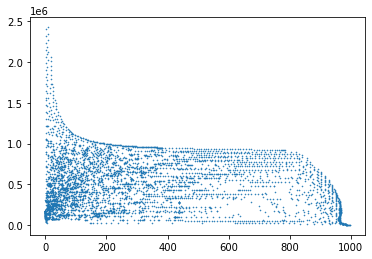

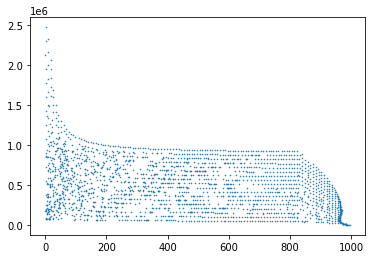

In [1465]:


# Pick interpolator
interpolator = model.interpolators[model.label_index_by_str["LV"]]
# Set number of iterations for regridding
NUM_ITERATIONS = 4

v = model.LV.v.flatten()
u = model.LV.u.flatten()
T = model.LV.T.flatten()
p = model.LV.p.flatten()
s = model.LV.s.flatten()
y_l = model.LV.y_l.flatten()
y_s = model.LV.y_s.flatten()

for i in range(NUM_ITERATIONS):

  (v_new, u_new, T_new, p_new, s_new, y_l_new, y_s_new) = regrid_LV(interpolator,
    left_range_rho_resolution=100,
    right_range_rho_resolution=15,
    u_resolution=40)
  if i == 0:
    plt.scatter(1.0 / v_new.ravel(), u_new.ravel(), s=0.3)

  v = np.concatenate((v.ravel(), v_new))
  u = np.concatenate((u.ravel(), u_new))
  T = np.concatenate((T.ravel(), T_new))
  p = np.concatenate((p.ravel(), p_new))
  s = np.concatenate((s.ravel(), s_new))
  y_l = np.concatenate((y_l.ravel(), y_l_new))
  y_s = np.concatenate((y_s.ravel(), y_s_new))

  interpolator = scipy.interpolate.LinearNDInterpolator(
    np.stack((1/v, u), axis=1),
    np.stack((T, p, s, y_l, y_s), axis=1),
  )

(v_new, u_new, T_new, p_new, s_new, y_l_new, y_s_new) = regrid_LV(interpolator)

plt.figure()
plt.scatter(1.0 / v_new.ravel(), u_new.ravel(), s=0.3)


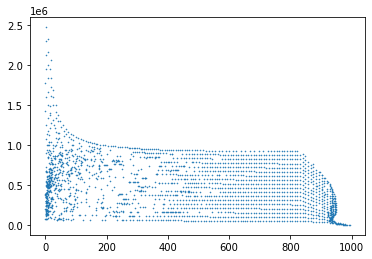

In [1443]:
plt.scatter(1.0 / v_new.ravel(), u_new.ravel(), s=0.3)


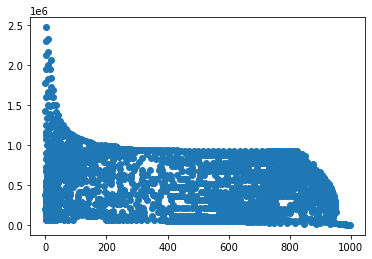

In [1435]:
(v_new, u_new, T_new, p_new, s_new, y_l_new, y_s_new) = regrid_LV(interpolator)
plt.scatter(1.0 / v_new.ravel(), u_new.ravel())

interpolator = scipy.interpolate.LinearNDInterpolator(
  np.stack((1/np.concatenate((v_base.ravel(), v_new)),
          np.concatenate((u_base.ravel(), u_new))), axis=1),
  np.stack((np.concatenate((T_base.ravel(), T_new)).ravel(),
            np.concatenate((p_base.ravel(), p_new)).ravel(),
            np.concatenate((s_base.ravel(), s_new)).ravel(),
            np.concatenate((y_l_base.ravel(), y_l_new)).ravel(),
            np.concatenate((y_s_base.ravel(), y_s_new)),), axis=1),
)

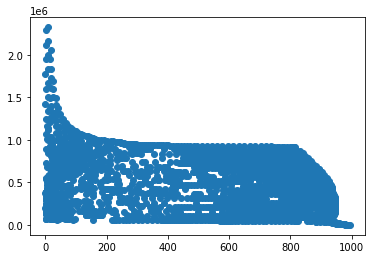

In [1436]:
(v_new, u_new, T_new, p_new, s_new, y_l_new, y_s_new) = regrid_LV(interpolator)
plt.scatter(1.0 / v_new.ravel(), u_new.ravel())

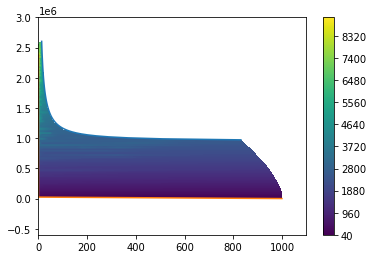

In [1351]:
# out
z_dat = np.reshape((out[:,2]), _u_mg.shape)
plt.contourf(_rho_mg, _u_mg, z_dat,
             levels=500)
plt.colorbar()

plt.plot(model.boundaries.LV_TMAX.rho,
         model.boundaries.LV_TMAX.u)
plt.plot(model.boundaries.LV_LSV.rho,
         model.boundaries.LV_LSV.u)

# plt.xlim(800, 1100)

In [1272]:
pts = np.stack((1/model.SV.v.ravel(), model.SV.u.ravel()), axis=1)
tri = scipy.spatial.Delaunay(pts, incremental=True)

In [1274]:
tri.simplices.shape

(2515, 3)

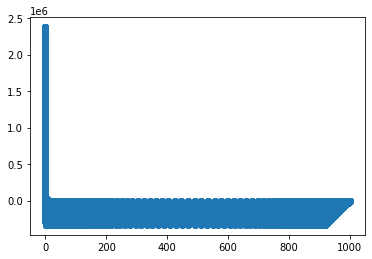

In [1338]:
plt.scatter(1/model.LSV.v.ravel(), model.LSV.u.ravel())


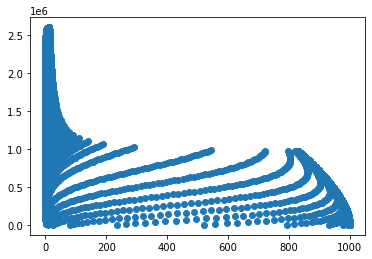

In [1265]:
plt.scatter(1/model.LV.v.ravel(), model.LV.u.ravel())

In [ ]:
input = np.stack((1000, .3e6,), axis=-1)
if len(input.shape) == 1:
  # Fix dimension of input ndarray of scalar inputs
  input = input[np.newaxis,:]
# (npoints, 5): T, p, s, y_l, y_s
rbfi(input).shape

(1, 5)

In [1095]:
np.stack((1/region.v.ravel(),
          region.u.ravel()), axis=-1)

array([[  1091.68530511, -80280.82392135],
       [  1089.66972168, -78093.14770413],
       [  1087.62166836, -75860.9017675 ],
       ...,
       [   961.32658343, 801080.41175243],
       [   955.59355657, 829835.11866127],
       [   949.78882017, 858601.89917392]])

#### Final testing

In [1483]:
import three_state_eos
model = three_state_eos.Model()

Populating LSV
Populating LV
Populating SV
Populating LS
Populating L
Populating V
Populating boundaries
Defining regions
Building interpolators
Remeshing LV region
Init done


In [1489]:
_rho_test_vec = np.concatenate((1/np.geomspace(1/800, 1e10, 200),
                                np.linspace(800, 1100, 1600)))
_u_test_vec = np.linspace(-.6e6, 3e6, 801)
_rho_mg, _u_mg = np.meshgrid(_rho_test_vec, _u_test_vec)
rho_test = _rho_mg.ravel()
u_test = _u_mg.ravel()

# Test point on boundary
rho_scalar = 13.198906510099981
u_scalar = 2602522.75447951

In [1490]:
out, region_labels_numeric = model.approx_rho_u(rho_test, u_test)

In [1492]:
T, p, s, y_l, y_s = out.T

In [1500]:
region_labels_numeric == 0

s[region_labels_numeric == 5] = np.nan

In [1499]:
model.label_str_by_index

array(['DEFAULT', 'L', 'LS', 'LSV', 'LV', 'LV_EXTRAPOLATE', 'SV', 'V'],
      dtype='<U14')

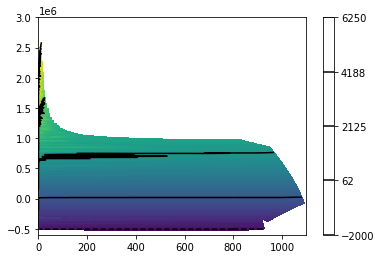

In [ ]:
plt.contourf(_rho_mg, _u_mg, np.reshape(, _u_mg.shape), levels=np.linspace(-2250, 6250, 100))
plt.contour(_rho_mg, _u_mg, np.reshape(s, _u_mg.shape), colors="k", levels=np.linspace(-2000, 6250, 5))
plt.colorbar()